# Tipo de entrega × bugs, criticidade e tempo de correção
**Análise exploratória e modelos preditivos com dados públicos de projetos ágeis (TAWOS)**

**Pergunta de pesquisa.** O tipo de coisa que se libera numa release (features novas, correções, tamanho, tipo de versão) está **associado** à quantidade de bugs identificados depois da publicação, à sua criticidade e ao tempo para corrigi-los? E quanto dessas informações permite **antecipar** esses desfechos? (H1 e H2 são as hipóteses confirmatórias; as demais análises da seção 6 são exploratórias.)

**Hipóteses**
- **H1:** a composição e o tipo da release (major/minor/patch, % de features, tamanho, componentes tocados) estão associados à quantidade de bugs pós-release.
- **H2:** dá para prever, já na abertura do bug, em que faixa de tempo ele será corrigido, usando atributos do bug e da release afetada.

**Dados.** TAWOS (Tawosi et al., MSR 2022): 458 mil issues de 39 projetos open source em Jira, DOI 10.5522/04/21308124, licença Apache 2.0. Este notebook usa 10 projetos com versões numeradas e mistura de features e bugs (Moodle, MongoDB Server, Titanium SDK, Mule, Nexus, Titanium Studio, Mesos, MongoDB Java Driver, Hyperledger Fabric, DotNetNuke).

**Bases** (geradas por `preparar_bases.py`):
- `bases/base_releases.csv`: 1 linha por release publicada → **Modelo 2 (risco da release)**
- `bases/base_bugs.csv`: 1 linha por bug corrigido → **Modelo 1 (tempo de correção)**

O dicionário de dados está em `bases/bases_tcc.xlsx`.

**Como executar.** No computador: abra este notebook na pasta do projeto e rode todas as células (≈ 4 min). No **Google Colab**: use o botão "Open in Colab" do README do repositório; a célula abaixo baixa o repositório e instala as bibliotecas automaticamente.

In [1]:
# Preparação para o Google Colab (no computador local esta célula não faz nada)
import os, sys, subprocess
REPO = "https://github.com/alineosilveira/tcc-governanca-operacional-ml.git"
if "google.colab" in sys.modules and not os.path.exists("bases"):
    subprocess.run(["git", "clone", "-q", REPO, "repo"], check=True)
    os.chdir("repo")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost", "shap", "statsmodels", "openpyxl"], check=True)
    print("Repositório baixado e bibliotecas instaladas.")

In [2]:
# Se faltar alguma biblioteca, descomente a linha abaixo:
# %pip install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels xgboost shap openpyxl

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
os.makedirs("figuras", exist_ok=True)
RANDOM_STATE = 42

def salvar(nome):
    plt.tight_layout()
    plt.savefig(f"figuras/{nome}.png", bbox_inches="tight")
    plt.show()

rel = pd.read_csv("bases/base_releases.csv", parse_dates=["Release_Date"])
bugs = pd.read_csv("bases/base_bugs.csv", parse_dates=["Creation_Date", "Resolution_Date"])
ORDEM_TIPO = ["major", "minor", "patch", "pre-release"]
print(f"Releases: {len(rel):,} | Bugs corrigidos: {len(bugs):,} | Projetos: {rel.Project_Key.nunique()}")

Releases: 1,233 | Bugs corrigidos: 55,649 | Projetos: 10


## 1. Visão geral dos dados

In [3]:
# 1.1 Elegibilidade: universo, filtros e perdas de cada base (parecer C4) e diagnósticos da reconstrução histórica
eleg = pd.read_csv("bases/elegibilidade.csv")
display(eleg)
display(pd.read_csv("bases/diagnosticos_reconstrucao.csv"))

,Base,Etapa,Registros,Perda_na_Etapa
0,Releases,Versões cadastradas nos dez projetos,2271,NaN
1,Releases,publicadas e com data de publicação,2007,264.0
2,Releases,com numeração identificável (x.y.z),1638,369.0
3,Releases,com ao menos um item entregue,1498,140.0
4,Releases,com 180 dias completos de acompanhamento,1426,72.0
5,Releases,com pelo menos três itens entregues na data de...,1233,193.0
6,Releases,com ao menos três releases anteriores no proje...,1203,30.0
7,Bugs,Bugs registrados nos dez projetos,111090,NaN
8,Bugs,com datas consistentes (resolução não anterior...,111090,-0.0
9,Bugs,abertos até 12 meses antes do fim da coleta (b...,105637,5453.0


,Diagnóstico,Valor
0,Vínculos de fix version (estado final),123087.0
1,Vínculos incluídos depois da publicação (retir...,7965.0
2,Vínculos removidos depois da publicação (devol...,5983.0
3,Bugs com versão afetada alterada após a abertura,24718.0
4,Sprints: itens com sprint definido na criação ...,9746.0
5,Validação sprints: itens cujo sprint final é u...,14209.0
6,Validação sprints: % reconstruídos como presen...,92.9


In [4]:
resumo = pd.DataFrame({
    "releases": rel.groupby("Project_Key").size(),
    "periodo_releases": rel.groupby("Project_Key").Release_Date.agg(lambda s: f"{s.min():%Y}–{s.max():%Y}"),
    "bugs_corrigidos": bugs.groupby("Project_Key").size(),
    "mediana_bugs_pos_release": rel.groupby("Project_Key").Bugs_Pos_Release.median(),
    "mediana_dias_correcao": bugs.groupby("Project_Key").Dias_Para_Corrigir.median().round(1),
}).sort_values("releases", ascending=False)
resumo

,releases,periodo_releases,bugs_corrigidos,mediana_bugs_pos_release,mediana_dias_correcao
Project_Key,,,,,
SERVER,358,2009–2020,11919,14.0,7.0
MDL,246,2004–2020,18441,46.0,16.4
TIMOB,138,2009–2020,8369,13.0,12.3
MULE,130,2005–2019,3622,11.0,11.0
NEXUS,113,2008–2020,3192,17.0,12.9
JAVA,77,2009–2020,563,4.0,5.7
MESOS,72,2012–2019,2756,6.0,16.0
TISTUD,49,2011–2019,1980,16.0,7.9
FAB,30,2016–2020,2596,15.5,7.5


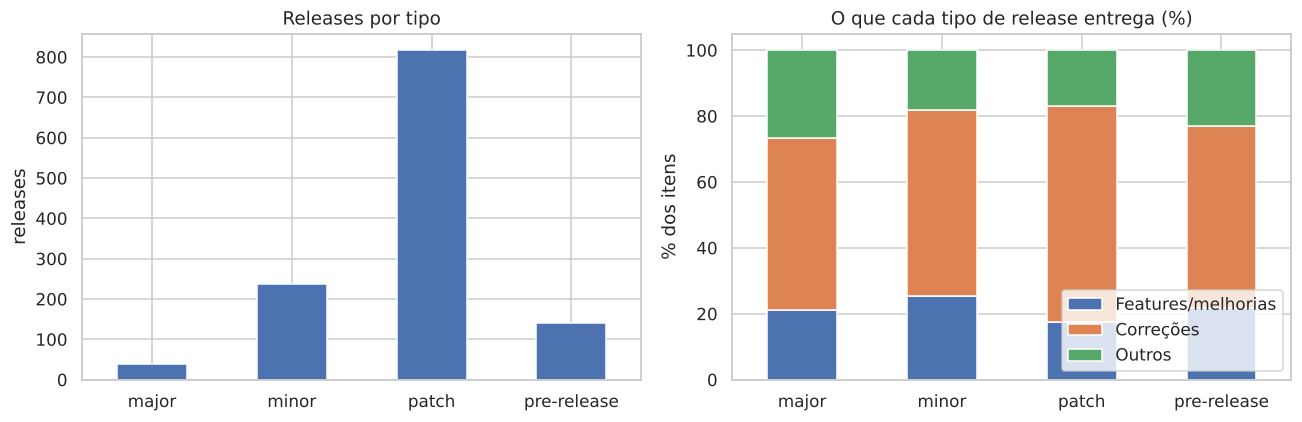

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
rel.Tipo_Release.value_counts().reindex(ORDEM_TIPO).plot.bar(ax=ax[0], color="#4C72B0", rot=0)
ax[0].set_title("Releases por tipo"); ax[0].set_xlabel(""); ax[0].set_ylabel("releases")
comp = rel.groupby("Tipo_Release")[["Qtd_Features", "Qtd_Correcoes", "Qtd_Outros"]].sum().reindex(ORDEM_TIPO)
(comp.div(comp.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, ax=ax[1], rot=0)
ax[1].set_title("O que cada tipo de release entrega (%)"); ax[1].set_xlabel(""); ax[1].set_ylabel("% dos itens")
ax[1].legend(["Features/melhorias", "Correções", "Outros"], loc="lower right")
salvar("01_tipos_release")

## 2. Análises tradicionais: release × bugs pós-release

**Bugs pós-release** são os bugs abertos até 180 dias após a publicação e atribuídos à versão afetada mais antiga, ou seja, à release que primeiro "carregou" o defeito. Cada bug conta uma única vez. Como proxy de **impacto em cliente**, usamos os bugs de prioridade alta ou bloqueante.

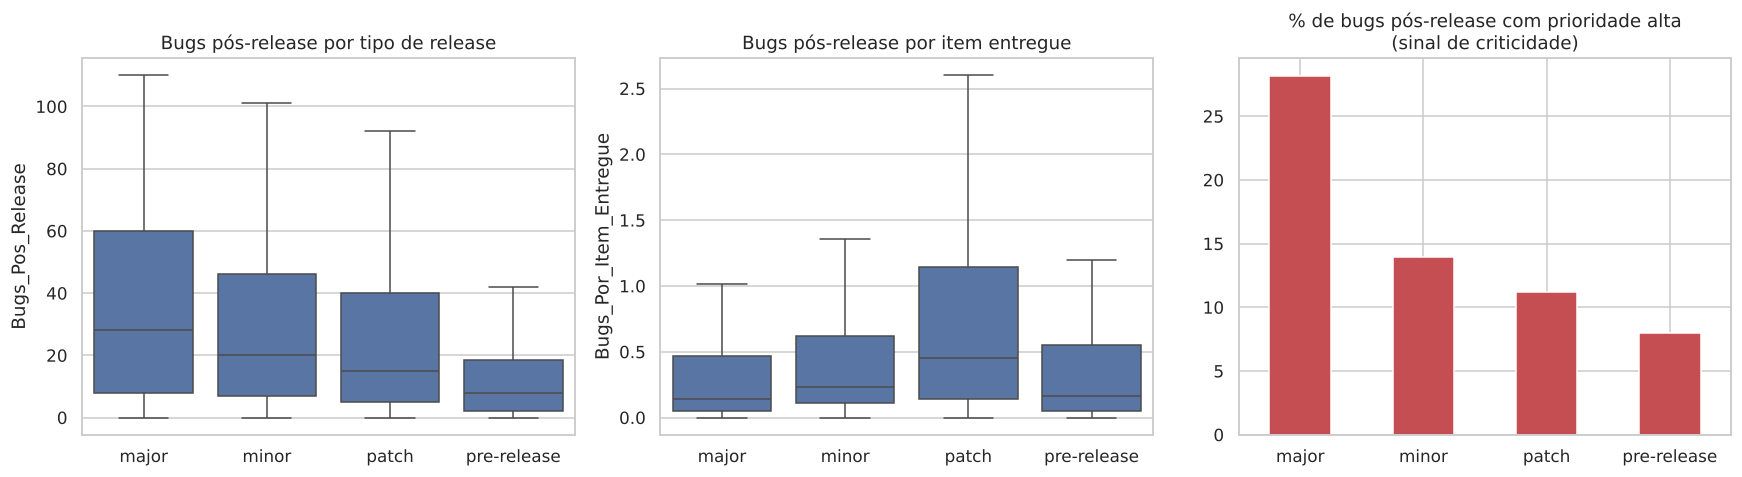

Mediana por tipo de release:


,Qtd_Itens,Pct_Features,Bugs_Pos_Release,Bugs_Pos_Release_Alta,Bugs_Por_Item_Entregue,Dias_Medianos_Correcao_Pos_Release
Tipo_Release,,,,,,
major,162.0,0.27,28.0,7.0,0.14,12.39
minor,61.0,0.27,20.0,1.0,0.23,20.57
patch,35.0,0.14,15.0,0.0,0.45,19.39
pre-release,35.5,0.20,8.0,0.0,0.17,7.14


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=rel, x="Tipo_Release", y="Bugs_Pos_Release", order=ORDEM_TIPO, ax=ax[0], showfliers=False)
ax[0].set_title("Bugs pós-release por tipo de release"); ax[0].set_xlabel("")
sns.boxplot(data=rel, x="Tipo_Release", y="Bugs_Por_Item_Entregue", order=ORDEM_TIPO, ax=ax[1], showfliers=False)
ax[1].set_title("Bugs pós-release por item entregue"); ax[1].set_xlabel("")
alta = rel.groupby("Tipo_Release")[["Bugs_Pos_Release_Alta", "Bugs_Pos_Release"]].sum().reindex(ORDEM_TIPO)
(alta.Bugs_Pos_Release_Alta / alta.Bugs_Pos_Release * 100).plot.bar(ax=ax[2], color="#C44E52", rot=0)
ax[2].set_title("% de bugs pós-release com prioridade alta\n(sinal de criticidade)"); ax[2].set_xlabel("")
salvar("02_bugs_por_tipo_release")

print("Mediana por tipo de release:")
display(rel.groupby("Tipo_Release")[["Qtd_Itens", "Pct_Features", "Bugs_Pos_Release", "Bugs_Pos_Release_Alta",
                                     "Bugs_Por_Item_Entregue", "Dias_Medianos_Correcao_Pos_Release"]]
        .median().reindex(ORDEM_TIPO).round(2))

### 2.1 Teste estatístico: o tipo de release muda a quantidade de bugs?
As distribuições são assimétricas, então usamos testes não paramétricos: Kruskal-Wallis para todos os grupos e Mann-Whitney par a par, com correção de Bonferroni.

In [7]:
from itertools import combinations

def kruskal_e_pares(df, grupo, valor, ordem):
    grupos = [df.loc[df[grupo] == g, valor].dropna() for g in ordem]
    h, p = stats.kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    eps2 = (h - len(grupos) + 1) / (n - len(grupos))   # tamanho de efeito (epsilon²)
    print(f"Kruskal-Wallis ({valor}): H = {h:.1f}, p = {p:.2e}, epsilon² = {eps2:.3f}")
    linhas = []
    pares = list(combinations(ordem, 2))
    for a, b in pares:
        x, y = df.loc[df[grupo] == a, valor].dropna(), df.loc[df[grupo] == b, valor].dropna()
        u, pu = stats.mannwhitneyu(x, y, alternative="two-sided")
        linhas.append((a, b, x.median(), y.median(), min(pu * len(pares), 1.0)))
    return pd.DataFrame(linhas, columns=["grupo_A", "grupo_B", "mediana_A", "mediana_B", "p_bonferroni"]).round(4)

display(kruskal_e_pares(rel, "Tipo_Release", "Bugs_Pos_Release", ORDEM_TIPO))
display(kruskal_e_pares(rel, "Tipo_Release", "Bugs_Por_Item_Entregue", ORDEM_TIPO))

Kruskal-Wallis (Bugs_Pos_Release): H = 43.3, p = 2.08e-09, epsilon² = 0.033


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,28.0,20.0,1.0000
1,major,patch,28.0,15.0,0.3821
2,major,pre-release,28.0,8.0,0.0002
3,minor,patch,20.0,15.0,0.1235
4,minor,pre-release,20.0,8.0,0.0000
5,patch,pre-release,15.0,8.0,0.0000


Kruskal-Wallis (Bugs_Por_Item_Entregue): H = 55.0, p = 6.99e-12, epsilon² = 0.042


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,0.1446,0.2326,0.3791
1,major,patch,0.1446,0.4500,0.0070
2,major,pre-release,0.1446,0.1667,1.0000
3,minor,patch,0.2326,0.4500,0.0002
4,minor,pre-release,0.2326,0.1667,0.0268
5,patch,pre-release,0.4500,0.1667,0.0000


### 2.2 Composição e tamanho da release × bugs (correlação de Spearman)

,variavel,rho_spearman,p_valor
2,Qtd_Correcoes,0.5424,0.0000
4,Qtd_Componentes_Tocados,0.5210,0.0000
0,Qtd_Itens,0.4991,0.0000
1,Qtd_Features,0.3524,0.0000
5,Qtd_Itens_Alta_Prioridade,0.2491,0.0000
6,Dias_Desde_Release_Anterior,0.0756,0.0081
3,Pct_Features,-0.0769,0.0069


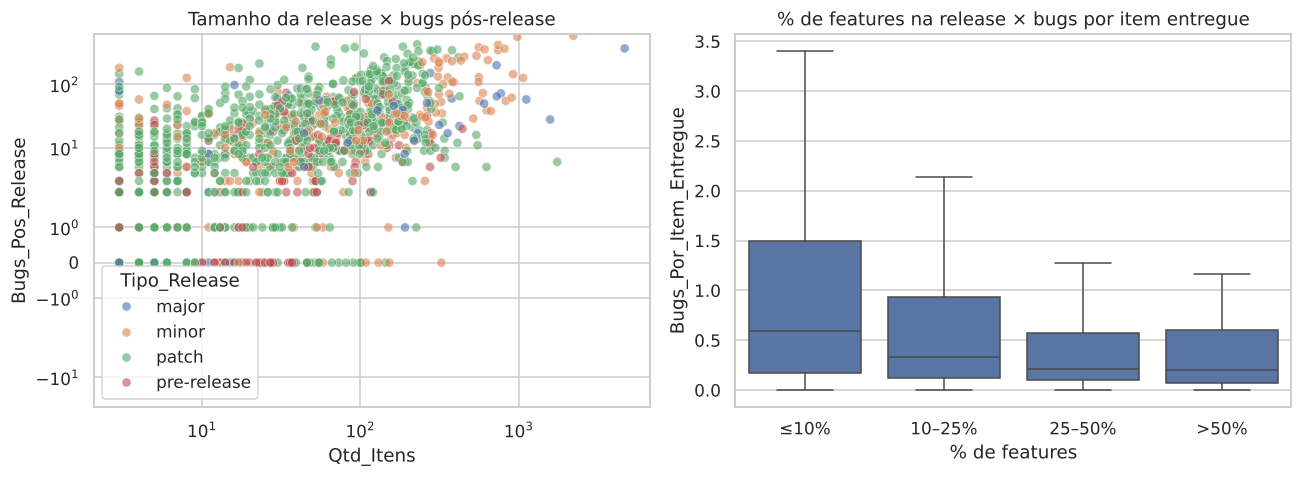

In [8]:
vars_rel = ["Qtd_Itens", "Qtd_Features", "Qtd_Correcoes", "Pct_Features", "Qtd_Componentes_Tocados",
            "Qtd_Itens_Alta_Prioridade", "Dias_Desde_Release_Anterior"]
corr = pd.DataFrame([(v, *stats.spearmanr(rel[v], rel.Bugs_Pos_Release, nan_policy="omit")) for v in vars_rel],
                    columns=["variavel", "rho_spearman", "p_valor"]).sort_values("rho_spearman", ascending=False)
display(corr.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=rel, x="Qtd_Itens", y="Bugs_Pos_Release", hue="Tipo_Release", hue_order=ORDEM_TIPO, alpha=.6, ax=ax[0])
ax[0].set(xscale="log", yscale="symlog", title="Tamanho da release × bugs pós-release")
rel["Faixa_Pct_Features"] = pd.cut(rel.Pct_Features, [-.01, .1, .25, .5, 1], labels=["≤10%", "10–25%", "25–50%", ">50%"])
sns.boxplot(data=rel, x="Faixa_Pct_Features", y="Bugs_Por_Item_Entregue", ax=ax[1], showfliers=False)
ax[1].set_title("% de features na release × bugs por item entregue"); ax[1].set_xlabel("% de features")
salvar("03_composicao_release")

### 2.3 Modelo estatístico explicativo (Binomial Negativa)
Controla ao mesmo tempo o tamanho da release, o mix e o projeto, que é o efeito fixo. O **exp(coef)** é a razão de taxas: por exemplo, 1,30 significa 30% mais bugs pós-release, mantendo o resto constante. É a evidência inferencial para **H1**.

In [9]:
import statsmodels.formula.api as smf

d = rel.copy()
d["log_itens"] = np.log1p(d.Qtd_Itens)
d["log_componentes"] = np.log1p(d.Qtd_Componentes_Tocados)
d["log_dias_ant"] = np.log1p(d.Dias_Desde_Release_Anterior.fillna(d.Dias_Desde_Release_Anterior.median()))
d["pct_features_10pp"] = d.Pct_Features * 10
d["pct_alta"] = d.Qtd_Itens_Alta_Prioridade / d.Qtd_Itens
nb = smf.negativebinomial(
    "Bugs_Pos_Release ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
    " + log_itens + log_componentes + log_dias_ant + C(Project_Key)", data=d).fit(disp=0, maxiter=200)
tab = pd.DataFrame({"razao_de_taxas": np.exp(nb.params), "IC95_inf": np.exp(nb.conf_int()[0]),
                    "IC95_sup": np.exp(nb.conf_int()[1]), "p_valor": nb.pvalues})
tab = tab[~tab.index.str.startswith("C(Project_Key)")].drop(index=["Intercept", "alpha"], errors="ignore")
print(f"Pseudo-R² (McFadden): {nb.prsquared:.3f}   n = {int(nb.nobs)}")
tab.round(3)

Pseudo-R² (McFadden): 0.067   n = 1233


,razao_de_taxas,IC95_inf,IC95_sup,p_valor
"C(Tipo_Release, Treatment('minor'))[T.major]",1.090,0.754,1.576,0.646
"C(Tipo_Release, Treatment('minor'))[T.patch]",0.629,0.528,0.749,0.000
"C(Tipo_Release, Treatment('minor'))[T.pre-release]",0.402,0.313,0.517,0.000
pct_features_10pp,0.917,0.876,0.961,0.000
pct_alta,3.671,2.311,5.832,0.000
log_itens,1.216,1.114,1.328,0.000
log_componentes,1.299,1.116,1.511,0.001
log_dias_ant,1.148,1.091,1.208,0.000


In [10]:
# Sensibilidade (parecer C13): releases do mesmo projeto não são independentes no tempo.
# Erros-padrão robustos agrupados por projeto-ano (≈ 100 grupos) em vez dos erros-padrão do modelo.
grp = pd.factorize(d.Project_Key + "_" + d.Ano.astype(str))[0]
nb_cl = smf.negativebinomial(
    "Bugs_Pos_Release ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
    " + log_itens + log_componentes + log_dias_ant + C(Project_Key)", data=d).fit(
    disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": grp})
comp_ep = pd.DataFrame({"razao_de_taxas": np.exp(nb.params), "p_modelo": nb.pvalues, "p_robusto_projeto_ano": nb_cl.pvalues,
                        "IC95_robusto_inf": np.exp(nb_cl.conf_int()[0]), "IC95_robusto_sup": np.exp(nb_cl.conf_int()[1])})
comp_ep[~comp_ep.index.str.startswith("C(Project_Key)")].drop(index=["Intercept", "alpha"], errors="ignore").round(3)

,razao_de_taxas,p_modelo,p_robusto_projeto_ano,IC95_robusto_inf,IC95_robusto_sup
"C(Tipo_Release, Treatment('minor'))[T.major]",1.090,0.646,0.610,0.782,1.520
"C(Tipo_Release, Treatment('minor'))[T.patch]",0.629,0.000,0.000,0.499,0.792
"C(Tipo_Release, Treatment('minor'))[T.pre-release]",0.402,0.000,0.000,0.280,0.578
pct_features_10pp,0.917,0.000,0.019,0.854,0.986
pct_alta,3.671,0.000,0.021,1.215,11.094
log_itens,1.216,0.000,0.005,1.060,1.395
log_componentes,1.299,0.001,0.024,1.035,1.629
log_dias_ant,1.148,0.000,0.000,1.087,1.214


## 3. Análises tradicionais: tempo de correção de bugs
`Dias_Para_Corrigir` é o tempo entre a abertura e a resolução do bug, ou seja, o tempo que o cliente espera.

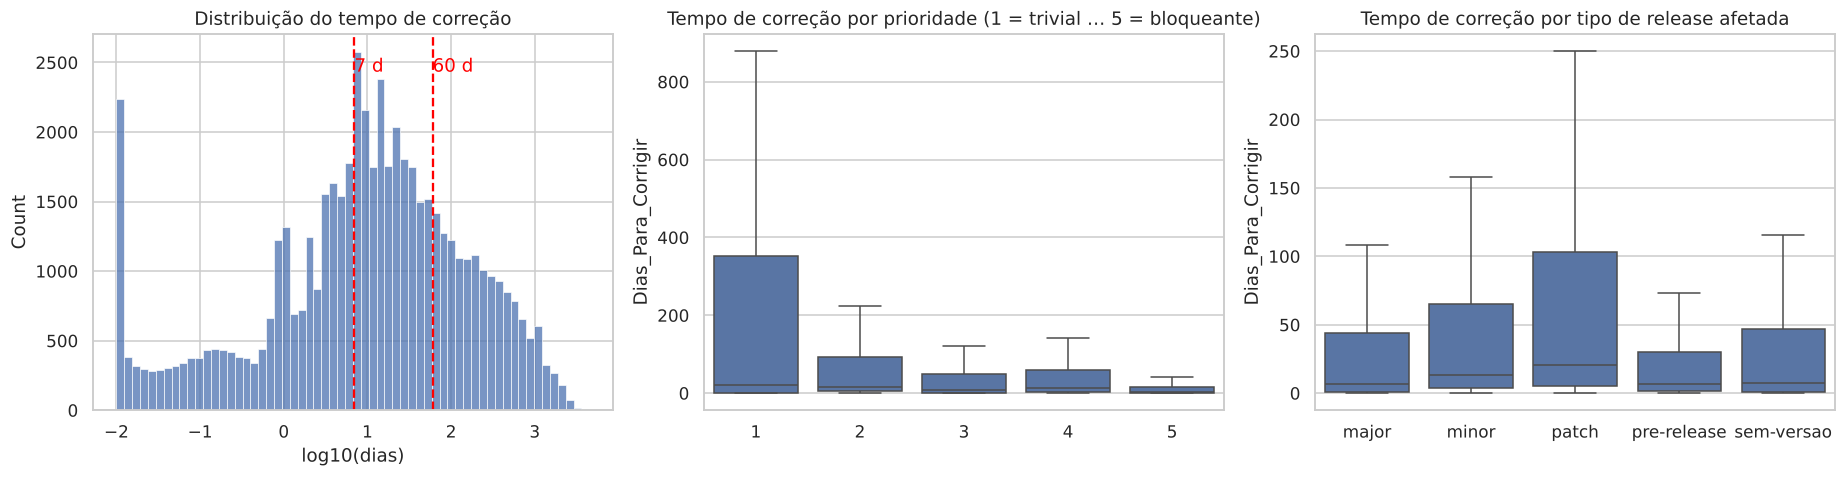

Faixa_Correcao,8_a_60_dias,ate_7_dias,mais_de_60_dias
Tipo_Release_Afetada,,,
major,28.4,50.2,21.5
minor,38.1,35.9,26.0
patch,37.7,30.3,32.0
pre-release,31.6,51.3,17.1
sem-versao,28.8,49.0,22.2


Kruskal-Wallis (Dias_Para_Corrigir): H = 1771.7, p = 0.00e+00, epsilon² = 0.032


,grupo_A,grupo_B,mediana_A,mediana_B,p_bonferroni
0,major,minor,6.9635,12.9357,0.0
1,major,patch,6.9635,20.4345,0.0
2,major,pre-release,6.9635,6.6112,1.0
3,major,sem-versao,6.9635,7.3503,1.0
4,minor,patch,12.9357,20.4345,0.0
5,minor,pre-release,12.9357,6.6112,0.0
6,minor,sem-versao,12.9357,7.3503,0.0
7,patch,pre-release,20.4345,6.6112,0.0
8,patch,sem-versao,20.4345,7.3503,0.0
9,pre-release,sem-versao,6.6112,7.3503,1.0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(np.log10(bugs.Dias_Para_Corrigir + 0.01), bins=60, ax=ax[0])
ax[0].set_title("Distribuição do tempo de correção"); ax[0].set_xlabel("log10(dias)")
for x, lbl in [(np.log10(7), "7 d"), (np.log10(60), "60 d")]:
    ax[0].axvline(x, color="red", ls="--"); ax[0].text(x, ax[0].get_ylim()[1]*.9, lbl, color="red")
sns.boxplot(data=bugs, x="Prioridade_Nivel", y="Dias_Para_Corrigir", ax=ax[1], showfliers=False)
ax[1].set_title("Tempo de correção por prioridade (1 = trivial … 5 = bloqueante)"); ax[1].set_xlabel("")
ordem_af = ORDEM_TIPO + ["sem-versao"]
sns.boxplot(data=bugs, x="Tipo_Release_Afetada", y="Dias_Para_Corrigir", order=ordem_af, ax=ax[2], showfliers=False)
ax[2].set_title("Tempo de correção por tipo de release afetada"); ax[2].set_xlabel("")
salvar("04_tempo_correcao")

display(pd.crosstab(bugs.Tipo_Release_Afetada, bugs.Faixa_Correcao, normalize="index").reindex(ordem_af).round(3) * 100)
display(kruskal_e_pares(bugs, "Tipo_Release_Afetada", "Dias_Para_Corrigir", ordem_af))

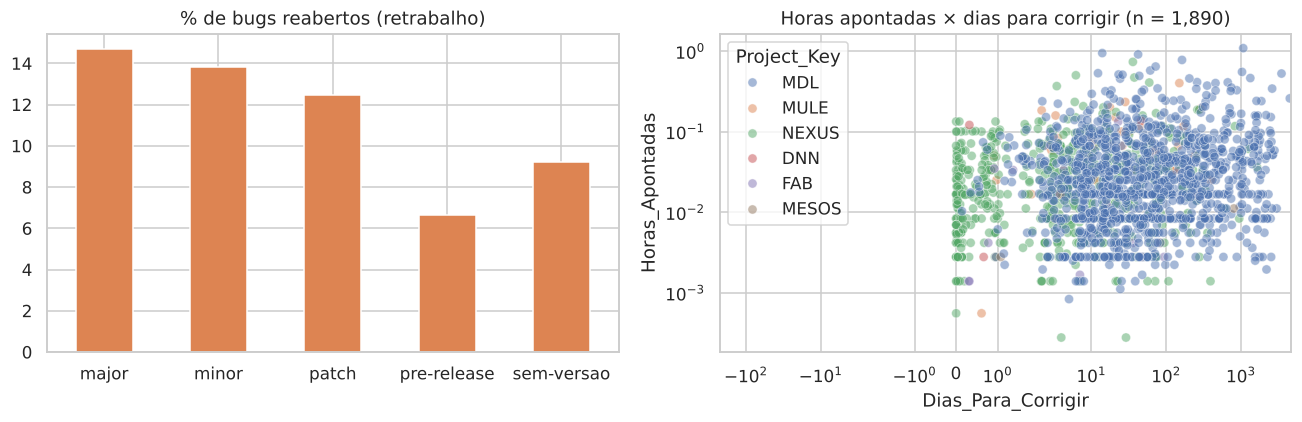

Horas apontadas preenchidas em 3.4% dos bugs (sobretudo MDL e NEXUS).
Spearman horas × dias: rho = 0.17 (p = 7.9e-14). O prazo de calendário não equivale ao esforço.


In [12]:
# Reaberturas (retrabalho) e horas apontadas
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(bugs.groupby("Tipo_Release_Afetada").Qtd_Reaberturas.apply(lambda s: (s > 0).mean() * 100)
     .reindex(ordem_af).plot.bar(ax=ax[0], color="#DD8452", rot=0))
ax[0].set_title("% de bugs reabertos (retrabalho)"); ax[0].set_xlabel("")
h = bugs.dropna(subset=["Horas_Apontadas"]).query("Horas_Apontadas > 0")
sns.scatterplot(data=h, x="Dias_Para_Corrigir", y="Horas_Apontadas", hue="Project_Key", alpha=.5, ax=ax[1])
ax[1].set(xscale="symlog", yscale="log", title=f"Horas apontadas × dias para corrigir (n = {len(h):,})")
salvar("05_reaberturas_horas")
rho, p = stats.spearmanr(h.Dias_Para_Corrigir, h.Horas_Apontadas)
print(f"Horas apontadas preenchidas em {bugs.Horas_Apontadas.notna().mean():.1%} dos bugs (sobretudo MDL e NEXUS).")
print(f"Spearman horas × dias: rho = {rho:.2f} (p = {p:.1e}). O prazo de calendário não equivale ao esforço.")

## 4. Modelo 1: prever a faixa de tempo de correção de um bug (H2)

- **Alvo:** `Faixa_Correcao`, com três classes: até 7 dias, de 8 a 60 dias e mais de 60 dias.
- **Features:** apenas o que se sabe **no dia em que o bug é aberto**, como prioridade inicial, texto, componentes, release afetada, carga do time e experiência de quem reportou.
- **Divisão temporal:** o treino usa bugs abertos até 30/06/2016 e o teste usa bugs abertos depois, simulando o uso real (aprender com o passado e prever o futuro).
- **Modelos comparados:** baseline (classe mais frequente), Regressão Logística, Random Forest e XGBoost.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (classification_report, f1_score, balanced_accuracy_score, roc_auc_score,
                             ConfusionMatrixDisplay, accuracy_score)
from xgboost import XGBClassifier

CAT_B = ["Project_Key", "Tipo_Release_Afetada"]
NUM_B = ["Prioridade_Nivel", "Tamanho_Titulo", "Tamanho_Descricao", "Tamanho_Codigo_Descricao",
         "Tem_Codigo_Na_Descricao", "Qtd_Componentes", "Qtd_Versoes_Afetadas", "Dias_Desde_Release_Afetada",
         "Itens_Release_Afetada", "Pct_Features_Release_Afetada", "Bugs_Abertos_No_Projeto",
         "Experiencia_Reporter", "Mes_Abertura", "Dia_Semana_Abertura", "Tem_Story_Point"]
CLASSES = ["ate_7_dias", "8_a_60_dias", "mais_de_60_dias"]

corte_b = pd.Timestamp("2016-07-01")
tr_b, te_b = bugs[bugs.Creation_Date < corte_b], bugs[bugs.Creation_Date >= corte_b]
Xtr_b, Xte_b = tr_b[CAT_B + NUM_B], te_b[CAT_B + NUM_B]
ytr_b = tr_b.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
yte_b = te_b.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
print(f"Treino: {len(tr_b):,} bugs | Teste: {len(te_b):,} bugs")
display(pd.DataFrame({"treino": ytr_b.value_counts(normalize=True).sort_index().values,
                      "teste": yte_b.value_counts(normalize=True).sort_index().values}, index=CLASSES).round(3))

def preproc(cat, num, escalar):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True)),
                 ("log", FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)), feature_names_out="one-to-one"))]
    if escalar:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                              ("num", Pipeline(num_steps), num)], verbose_feature_names_out=False)

modelos_b = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1),
}

def avaliar(modelos, Xtr, ytr, Xte, yte, cat, num, multiclasse):
    res, fitted = [], {}
    for nome, m in modelos.items():
        pipe = Pipeline([("prep", preproc(cat, num, escalar=nome.startswith("Regressão"))), ("modelo", m)])
        if nome == "XGBoost" and multiclasse:   # balanceia classes via peso de amostra
            w = ytr.map(1 / ytr.value_counts(normalize=True)).values
            pipe.fit(Xtr, ytr, modelo__sample_weight=w)
        else:
            pipe.fit(Xtr, ytr)
        pred, proba = pipe.predict(Xte), pipe.predict_proba(Xte)
        auc = roc_auc_score(yte, proba, multi_class="ovr") if multiclasse else roc_auc_score(yte, proba[:, 1])
        res.append({"modelo": nome, "acuracia": accuracy_score(yte, pred),
                    "acuracia_balanceada": balanced_accuracy_score(yte, pred),
                    "F1_macro": f1_score(yte, pred, average="macro"), "AUC": auc})
        fitted[nome] = pipe
    return pd.DataFrame(res).set_index("modelo").round(3), fitted

res_b, fit_b = avaliar(modelos_b, Xtr_b, ytr_b, Xte_b, yte_b, CAT_B, NUM_B, multiclasse=True)
res_b

Treino: 40,089 bugs | Teste: 15,560 bugs


,treino,teste
ate_7_dias,0.411,0.394
8_a_60_dias,0.316,0.392
mais_de_60_dias,0.273,0.214


,acuracia,acuracia_balanceada,F1_macro,AUC
modelo,,,,
Baseline (classe mais frequente),0.394,0.333,0.188,0.500
Regressão Logística,0.438,0.426,0.420,0.606
Random Forest,0.458,0.433,0.427,0.631
XGBoost,0.453,0.438,0.428,0.626


Melhor modelo (F1 macro): XGBoost

                 precision    recall  f1-score   support

     ate_7_dias      0.513     0.631     0.566      6128
    8_a_60_dias      0.491     0.331     0.395      6098
mais_de_60_dias      0.300     0.352     0.324      3334

       accuracy                          0.453     15560
      macro avg      0.435     0.438     0.428     15560
   weighted avg      0.459     0.453     0.447     15560



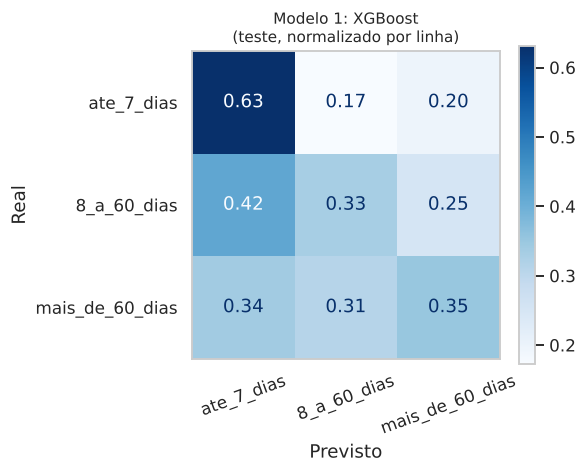

In [14]:
melhor_b = res_b.drop(index="Baseline (classe mais frequente)").F1_macro.idxmax()
print(f"Melhor modelo (F1 macro): {melhor_b}\n")
pred = fit_b[melhor_b].predict(Xte_b)
print(classification_report(yte_b, pred, target_names=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(yte_b, pred, display_labels=CLASSES, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax, xticks_rotation=20)
ax.set_title(f"Modelo 1: {melhor_b}\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("06_modelo1_matriz_confusao")

### 4.1 Validação cruzada temporal (robustez)
Repete o treino e teste em 4 janelas no tempo (`TimeSeriesSplit`) para mostrar que o resultado não depende de um único corte.

In [15]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
X_all, y_all = bugs[CAT_B + NUM_B], bugs.Faixa_Correcao.map({c: i for i, c in enumerate(CLASSES)})
cv_res = {}
for nome in ["Regressão Logística", "XGBoost"]:
    pipe = Pipeline([("prep", preproc(CAT_B, NUM_B, escalar=nome.startswith("Regressão"))), ("modelo", modelos_b[nome])])
    s = cross_validate(pipe, X_all, y_all, cv=TimeSeriesSplit(n_splits=4), scoring=["f1_macro", "balanced_accuracy"])
    cv_res[nome] = {"F1_macro (média ± dp)": f"{s['test_f1_macro'].mean():.3f} ± {s['test_f1_macro'].std():.3f}",
                    "Acurácia bal. (média ± dp)": f"{s['test_balanced_accuracy'].mean():.3f} ± {s['test_balanced_accuracy'].std():.3f}"}
pd.DataFrame(cv_res).T

,F1_macro (média ± dp),Acurácia bal. (média ± dp)
Regressão Logística,0.386 ± 0.025,0.402 ± 0.012
XGBoost,0.414 ± 0.021,0.436 ± 0.008


### 4.2 Explicabilidade (SHAP): o que mais pesa no tempo de correção?

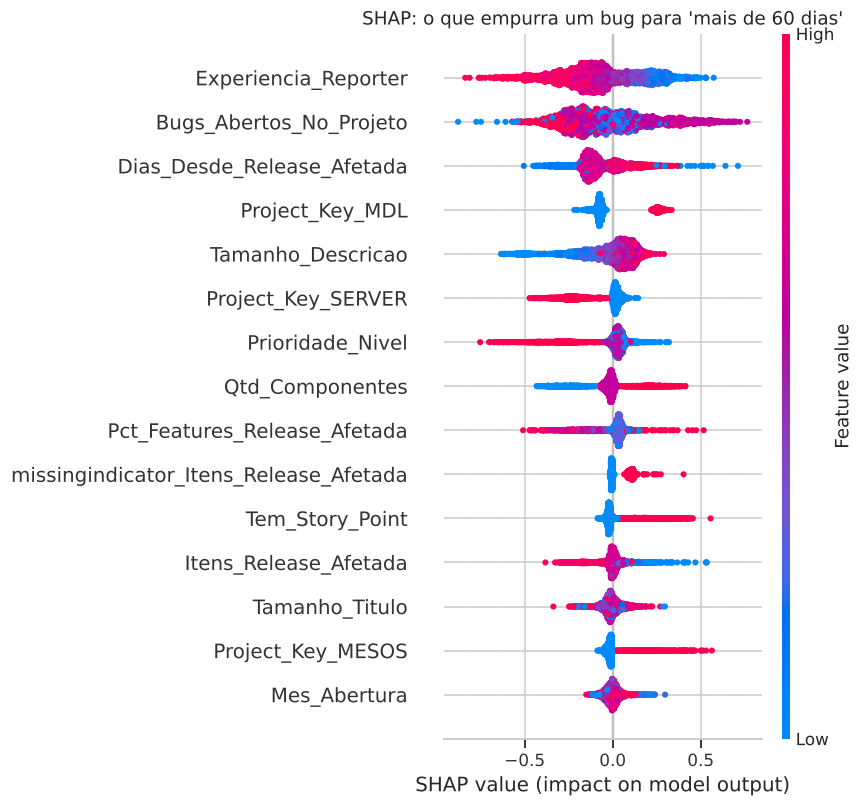

In [16]:
import shap
xgb_pipe = fit_b["XGBoost"]
Xs = xgb_pipe.named_steps["prep"].transform(Xte_b.sample(3000, random_state=RANDOM_STATE))
nomes = xgb_pipe.named_steps["prep"].get_feature_names_out()
sv = shap.TreeExplainer(xgb_pipe.named_steps["modelo"]).shap_values(Xs)
sv_longa = sv[:, :, 2] if np.ndim(sv) == 3 else sv[2]       # classe "mais_de_60_dias"
shap.summary_plot(sv_longa, Xs, feature_names=nomes, max_display=15, show=False)
plt.title("SHAP: o que empurra um bug para 'mais de 60 dias'")
salvar("07_modelo1_shap")

## 5. Modelo 2: prever se uma release será de alto risco (H1)

- **Alvo:** `Alto_Risco = 1` quando os bugs pós-release ficam acima da **mediana das releases anteriores do mesmo projeto** (é preciso ter ao menos três releases anteriores). A comparação com o próprio histórico neutraliza o porte de cada projeto e **não usa informação futura**.
- **Composição da release:** reconstruída para a **data de publicação** pelo histórico de alterações (itens vinculados depois da publicação não contam).
- **Features:** o que se sabe **no dia da publicação**: tipo da release, mix, tamanho, componentes, prioridade dos itens e intervalo desde a release anterior.
- **Divisão temporal:** o treino usa releases até 31/12/2016 e o teste usa releases a partir de 2017.
- Como a amostra é menor (cerca de 1.250 releases), também usamos modelos mais simples e regularizados.

In [17]:
CAT_R = ["Project_Key", "Tipo_Release"]
NUM_R = ["Qtd_Itens", "Qtd_Features", "Qtd_Correcoes", "Qtd_Outros", "Pct_Features", "Pct_Correcoes",
         "Qtd_Itens_Alta_Prioridade", "Story_Points_Total", "Qtd_Componentes_Tocados",
         "Tamanho_Medio_Descricao", "Dias_Desde_Release_Anterior"]
corte_r = pd.Timestamp("2017-01-01")
relm = rel[rel.Alto_Risco >= 0]          # releases com ao menos três releases anteriores no projeto
tr_r, te_r = relm[relm.Release_Date < corte_r], relm[relm.Release_Date >= corte_r]
print(f"Treino: {len(tr_r)} releases | Teste: {len(te_r)} releases | % alto risco no teste: {te_r.Alto_Risco.mean():.1%}")

modelos_r = {
    "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_depth=8,
                                            class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.03, max_depth=3, subsample=0.8,
                             colsample_bytree=0.8, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
res_r, fit_r = avaliar(modelos_r, tr_r[CAT_R + NUM_R], tr_r.Alto_Risco, te_r[CAT_R + NUM_R], te_r.Alto_Risco,
                       CAT_R, NUM_R, multiclasse=False)
res_r

Treino: 789 releases | Teste: 414 releases | % alto risco no teste: 32.1%


,acuracia,acuracia_balanceada,F1_macro,AUC
modelo,,,,
Baseline (classe mais frequente),0.321,0.500,0.243,0.500
Regressão Logística,0.604,0.603,0.584,0.656
Random Forest,0.606,0.617,0.591,0.666
XGBoost,0.565,0.606,0.561,0.668


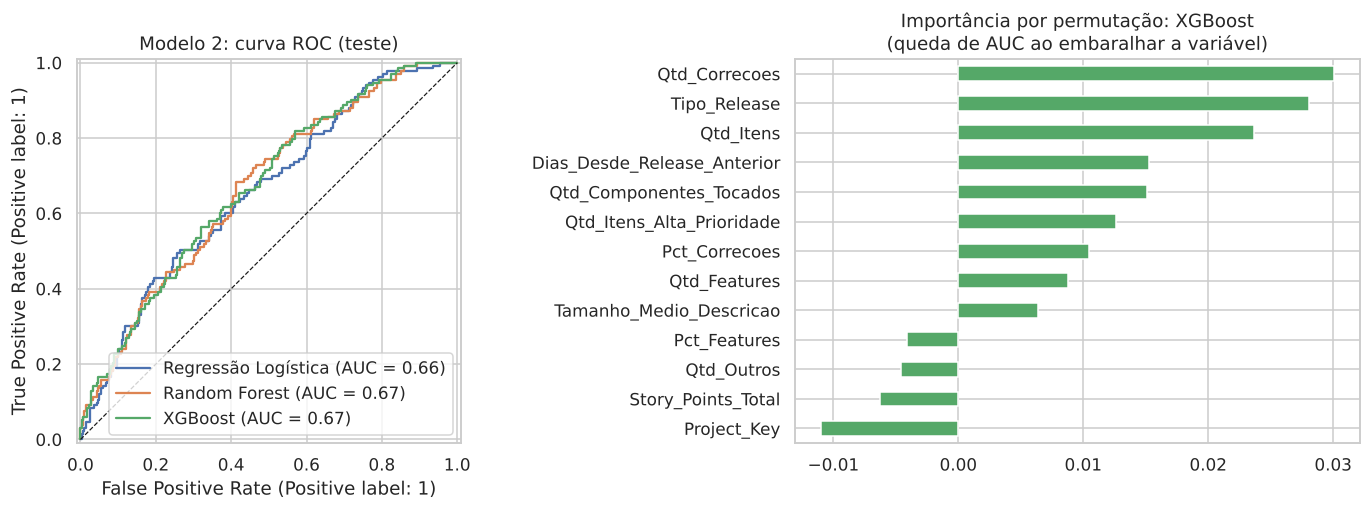

Melhor modelo (AUC): XGBoost
              precision    recall  f1-score   support

 baixo risco      0.789     0.491     0.605       281
  alto risco      0.402     0.722     0.516       133

    accuracy                          0.565       414
   macro avg      0.595     0.606     0.561       414
weighted avg      0.664     0.565     0.577       414



In [18]:
from sklearn.metrics import RocCurveDisplay
from sklearn.inspection import permutation_importance

melhor_r = res_r.drop(index="Baseline (classe mais frequente)").AUC.idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    RocCurveDisplay.from_estimator(fit_r[nome], te_r[CAT_R + NUM_R], te_r.Alto_Risco, ax=ax[0], name=nome)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].set_title("Modelo 2: curva ROC (teste)")
pi = permutation_importance(fit_r[melhor_r], te_r[CAT_R + NUM_R], te_r.Alto_Risco, scoring="roc_auc",
                            n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=CAT_R + NUM_R).sort_values()
imp.plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"Importância por permutação: {melhor_r}\n(queda de AUC ao embaralhar a variável)")
salvar("08_modelo2_roc_importancia")
print(f"Melhor modelo (AUC): {melhor_r}")
print(classification_report(te_r.Alto_Risco, fit_r[melhor_r].predict(te_r[CAT_R + NUM_R]),
                            target_names=["baixo risco", "alto risco"], digits=3))

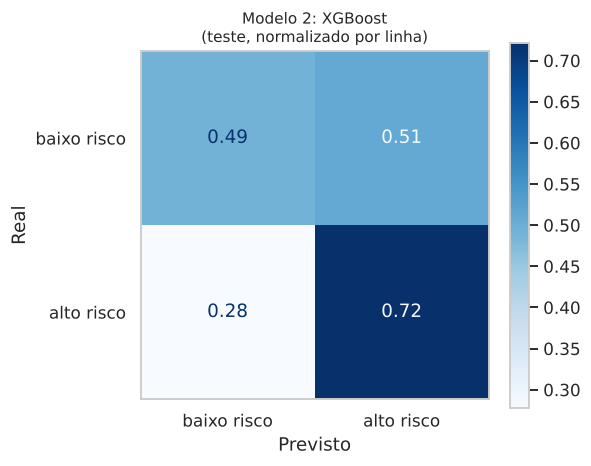

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_r[melhor_r], te_r[CAT_R + NUM_R], te_r.Alto_Risco, display_labels=["baixo risco", "alto risco"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("Modelo 2: " + melhor_r + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("08b_modelo2_matriz_confusao")

# 6. Perguntas complementares
As perguntas abaixo usam a mesma base e se conectam às rotinas de PMO do trabalho: previsto × realizado nos sprints, distribuição do trabalho registrado, concentração de trabalho, retrabalho e sinais de criticidade dos bugs. São análises **exploratórias**; as hipóteses confirmatórias são H1 e H2.

In [20]:
from sklearn.metrics import average_precision_score, precision_recall_curve, PrecisionRecallDisplay

def avaliar_bin(Xtr, ytr, Xte, yte, cat, num):
    peso = (1 - ytr.mean()) / ytr.mean()
    modelos = {
        "Baseline (classe mais frequente)": DummyClassifier(strategy="most_frequent"),
        "Regressão Logística": LogisticRegression(max_iter=3000, class_weight="balanced"),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=10, class_weight="balanced",
                                                n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                 scale_pos_weight=peso, eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
    }
    res, fitted = [], {}
    for nome, m in modelos.items():
        pipe = Pipeline([("prep", preproc(cat, num, escalar=nome.startswith("Regressão"))), ("modelo", m)]).fit(Xtr, ytr)
        proba, pred = pipe.predict_proba(Xte)[:, 1], pipe.predict(Xte)
        res.append({"modelo": nome, "AUC": roc_auc_score(yte, proba),
                    "PR_AUC (precisão média)": average_precision_score(yte, proba),
                    "taxa_base_positivos": yte.mean(),
                    "recall_positivos": (pred[yte.values == 1] == 1).mean(),
                    "precisao_positivos": yte.values[pred == 1].mean() if (pred == 1).any() else 0,
                    "F1_macro": f1_score(yte, pred, average="macro")})
        fitted[nome] = pipe
    return pd.DataFrame(res).set_index("modelo").round(3), fitted

## 6.1 Previsto × realizado nos sprints (P1)
A partir do histórico do campo *Sprint* de cada item, reconstruímos para cada sprint fechado:
- o que foi **planejado**: itens no sprint até 1 dia após o início;
- o que foi **adicionado** ou **removido** durante o sprint;
- o que foi **concluído** e o que **escorregou** para o sprint seguinte (*spillover*).

São 8 projetos com sprints registrados. SERVER e DNN usam sprints, mas a base não traz as datas deles.

In [21]:
spr = pd.read_csv("bases/base_sprints.csv", parse_dates=["Start_Date", "Complete_Date"])
its = pd.read_csv("bases/base_itens_sprint.csv", parse_dates=["Start_Date"])
print(f"{len(spr):,} sprints | {len(its):,} itens planejados")
tab = spr.groupby("Project_Key").agg(
    sprints=("Sprint_ID", "size"),
    duracao_mediana_dias=("Duracao_Dias", "median"),
    itens_planejados_mediana=("Itens_Planejados", "median"),
    taxa_cumprimento_mediana=("Taxa_Cumprimento", "median"),
    escorregamento_mediano=("Taxa_Escorregamento", "median"),
    escopo_adicionado_mediano=("Pct_Escopo_Adicionado", "median"),
    pct_SP_entregue_mediano=("Pct_SP_Entregue", "median"),
).round(2).sort_values("taxa_cumprimento_mediana")
display(tab)
print(f"Geral: mediana de {spr.Taxa_Cumprimento.median():.0%} do planejado entregue no próprio sprint; "
      f"escopo adicionado durante o sprint = {spr.Pct_Escopo_Adicionado.median():.0%} do planejado (mediana).")

993 sprints | 15,189 itens planejados


,sprints,duracao_mediana_dias,itens_planejados_mediana,taxa_cumprimento_mediana,escorregamento_mediano,escopo_adicionado_mediano,pct_SP_entregue_mediano
Project_Key,,,,,,,
FAB,37,15.35,8.0,0.25,0.64,1.13,0.11
TIMOB,228,14.29,17.5,0.32,0.43,0.65,0.21
MESOS,180,14.00,10.0,0.33,0.59,0.46,0.27
TISTUD,126,14.01,10.0,0.41,0.25,0.33,0.37
MDL,115,20.79,15.0,0.43,0.50,0.37,0.29
MULE,184,13.96,10.0,0.63,0.30,0.56,0.60
JAVA,27,21.93,8.0,0.75,0.14,1.60,0.05
NEXUS,96,13.98,6.0,0.83,0.21,0.75,0.89


Geral: mediana de 43% do planejado entregue no próprio sprint; escopo adicionado durante o sprint = 50% do planejado (mediana).


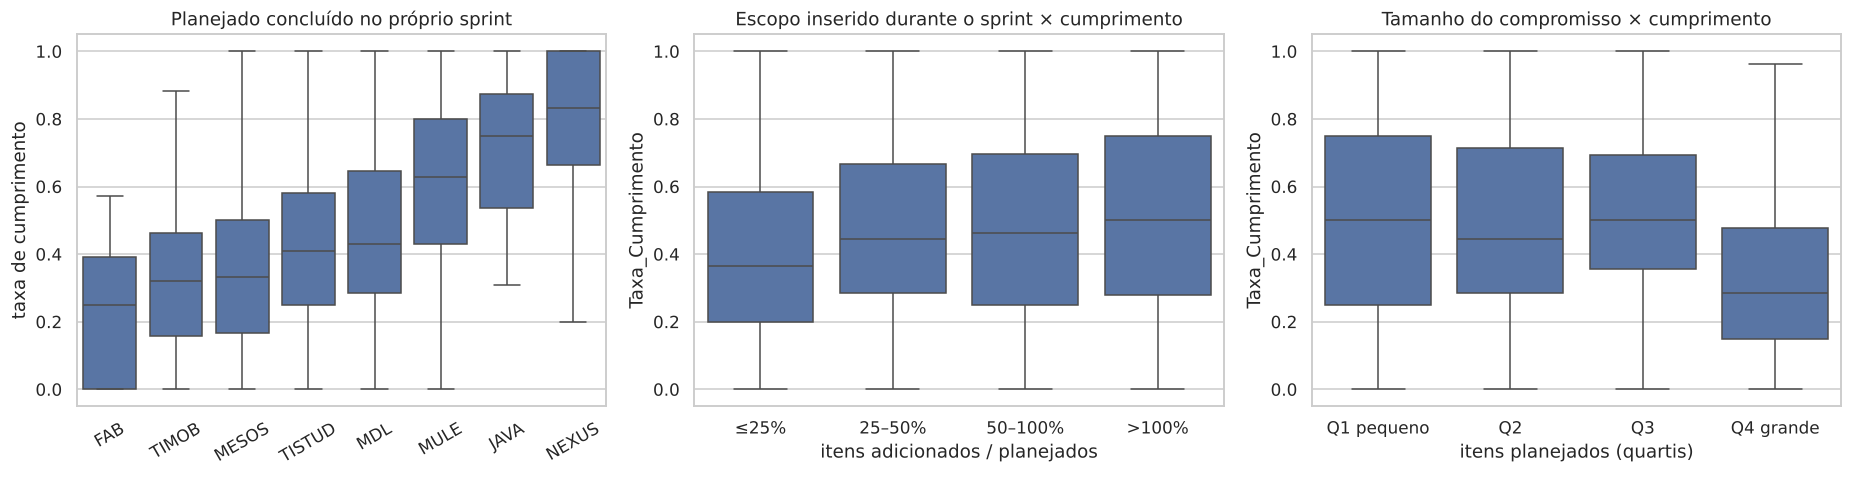

Spearman Pct_Escopo_Adicionado    × taxa de cumprimento: rho = +0.137 (p = 1.4e-05)
Spearman Itens_Planejados         × taxa de cumprimento: rho = -0.177 (p = 2.1e-08)
Spearman Pessoas_No_Sprint        × taxa de cumprimento: rho = -0.215 (p = 7.1e-12)
Spearman Pct_Bugs_Planejados      × taxa de cumprimento: rho = +0.076 (p = 1.7e-02)
Spearman Duracao_Dias             × taxa de cumprimento: rho = -0.025 (p = 4.2e-01)

Previsibilidade: usar a média dos 3 sprints anteriores como previsão de velocity erra, na mediana, 55%.


In [22]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=spr, x="Project_Key", y="Taxa_Cumprimento", order=tab.index, ax=ax[0], showfliers=False)
ax[0].set(title="Planejado concluído no próprio sprint", xlabel="", ylabel="taxa de cumprimento")
ax[0].tick_params(axis="x", rotation=30)
spr["Faixa_Escopo_Adicionado"] = pd.cut(spr.Pct_Escopo_Adicionado, [-.01, .25, .5, 1, np.inf], labels=["≤25%", "25–50%", "50–100%", ">100%"])
sns.boxplot(data=spr, x="Faixa_Escopo_Adicionado", y="Taxa_Cumprimento", ax=ax[1], showfliers=False)
ax[1].set(title="Escopo inserido durante o sprint × cumprimento", xlabel="itens adicionados / planejados")
spr["Faixa_Tamanho"] = pd.qcut(spr.Itens_Planejados, 4, labels=["Q1 pequeno", "Q2", "Q3", "Q4 grande"])
sns.boxplot(data=spr, x="Faixa_Tamanho", y="Taxa_Cumprimento", ax=ax[2], showfliers=False)
ax[2].set(title="Tamanho do compromisso × cumprimento", xlabel="itens planejados (quartis)")
salvar("15_sprints_cumprimento")

for v in ["Pct_Escopo_Adicionado", "Itens_Planejados", "Pessoas_No_Sprint", "Pct_Bugs_Planejados", "Duracao_Dias"]:
    r, p = stats.spearmanr(spr[v], spr.Taxa_Cumprimento, nan_policy="omit")
    print(f"Spearman {v:24s} × taxa de cumprimento: rho = {r:+.3f} (p = {p:.1e})")
# Previsibilidade: a velocity dos últimos sprints prevê a do próximo?
v = spr.dropna(subset=["Velocity_Media_3_Anteriores"])
v = v[v.Velocity_Media_3_Anteriores > 0]
erro = (v.Velocity_SP - v.Velocity_Media_3_Anteriores).abs() / v.Velocity_Media_3_Anteriores
print(f"\nPrevisibilidade: usar a média dos 3 sprints anteriores como previsão de velocity erra, na mediana, {erro.median():.0%}.")

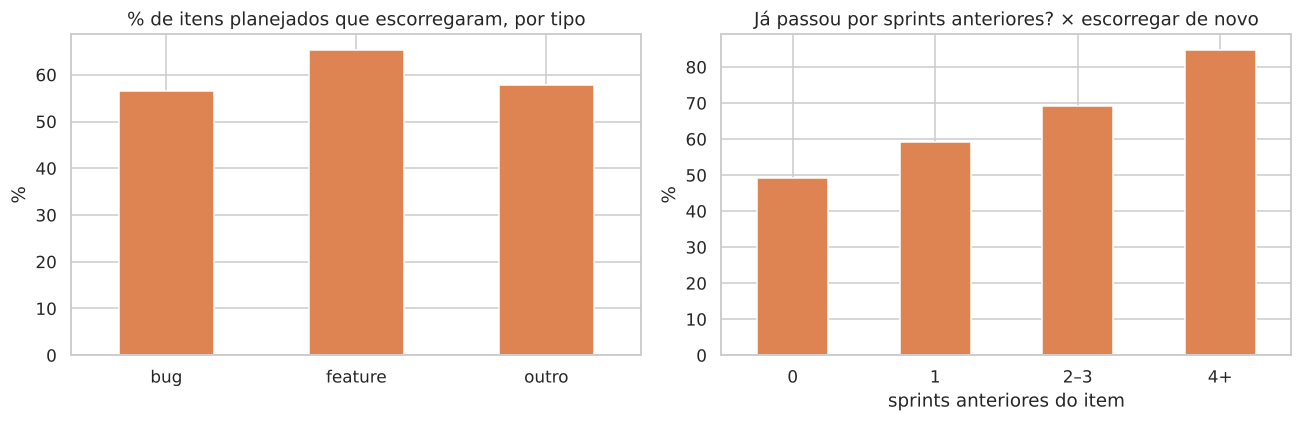

Modelo: prever, no início do sprint, se um item planejado NÃO será concluído dentro dele
Treino: 10,609 itens (até 11/2017) | Teste: 4,580 itens


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.739,0.739,1.000,0.739,0.425
Regressão Logística,0.684,0.860,0.739,0.781,0.794,0.602
Random Forest,0.665,0.827,0.739,0.765,0.802,0.609
XGBoost,0.664,0.836,0.739,0.711,0.805,0.596


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(its.groupby("Tipo_Item").Nao_Concluiu_No_Sprint.mean() * 100).plot.bar(ax=ax[0], rot=0, color="#DD8452")
ax[0].set(title="% de itens planejados que escorregaram, por tipo", xlabel="", ylabel="%")
its["Faixa_Carregado"] = pd.cut(its.Vezes_Em_Sprints_Anteriores, [-1, 0, 1, 3, np.inf], labels=["0", "1", "2–3", "4+"])
(its.groupby("Faixa_Carregado").Nao_Concluiu_No_Sprint.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#DD8452")
ax[1].set(title="Já passou por sprints anteriores? × escorregar de novo", xlabel="sprints anteriores do item", ylabel="%")
salvar("16_sprints_itens")

print("Modelo: prever, no início do sprint, se um item planejado NÃO será concluído dentro dele")
CAT_S = ["Project_Key", "Tipo_Item"]
NUM_S = ["Prioridade_Nivel", "Story_Point", "Tem_Story_Point", "Tamanho_Descricao", "Qtd_Componentes",
         "Tem_Responsavel", "Itens_Do_Responsavel_No_Sprint", "Vezes_Em_Sprints_Anteriores",
         "Duracao_Sprint_Dias", "Itens_Planejados", "SP_Planejados", "Pessoas_No_Sprint", "Taxa_Cumprimento_Anterior"]
corte_s = its.Start_Date.quantile(0.7)
tr_s, te_s = its[its.Start_Date < corte_s], its[its.Start_Date >= corte_s]
print(f"Treino: {len(tr_s):,} itens (até {corte_s:%m/%Y}) | Teste: {len(te_s):,} itens")
res_s, fit_s = avaliar_bin(tr_s[CAT_S + NUM_S], tr_s.Nao_Concluiu_No_Sprint, te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, CAT_S, NUM_S)
res_s

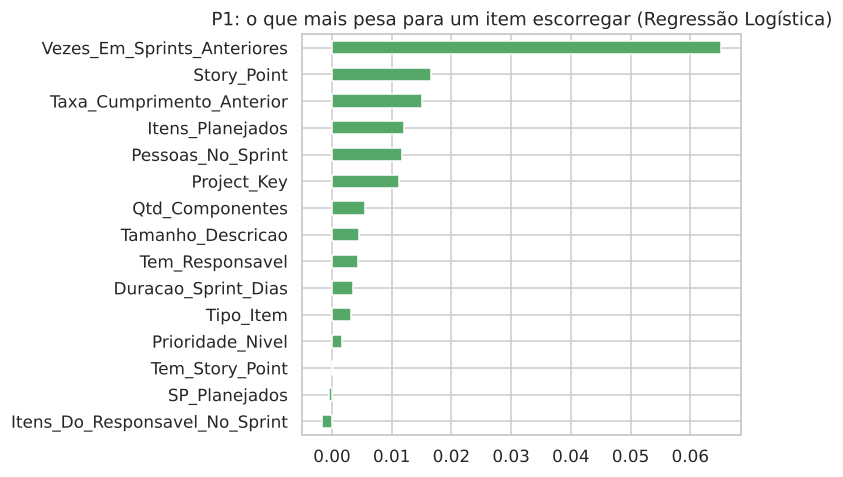

In [24]:
melhor_s = res_s.drop(index="Baseline (classe mais frequente)").AUC.idxmax()
pi = permutation_importance(fit_s[melhor_s], te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, scoring="roc_auc",
                            n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 4.5))
pd.Series(pi.importances_mean, index=CAT_S + NUM_S).sort_values().plot.barh(ax=ax, color="#55A868")
ax.set_title(f"P1: o que mais pesa para um item escorregar ({melhor_s})")
salvar("17_sprints_modelo")

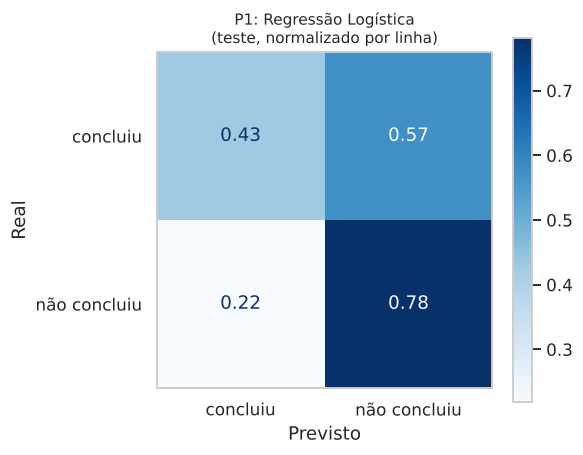

In [25]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_s[melhor_s], te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, display_labels=["concluiu", "não concluiu"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P1: " + melhor_s + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("17b_sprints_matriz_confusao")

## 6.2 Distribuição do trabalho registrado: sustentação × evolução (P3)
`base_capacidade_mensal.csv` traz, mês a mês e por projeto, os itens resolvidos em **sustentação** (bugs) e em **evolução** (features e melhorias). A medida é a **quantidade de itens resolvidos**, não horas nem capacidade real da equipe (as horas apontadas são escassas na base). A pergunta é se um pico de bugs está associado a uma fatia maior de correções nos itens resolvidos dos períodos seguintes.

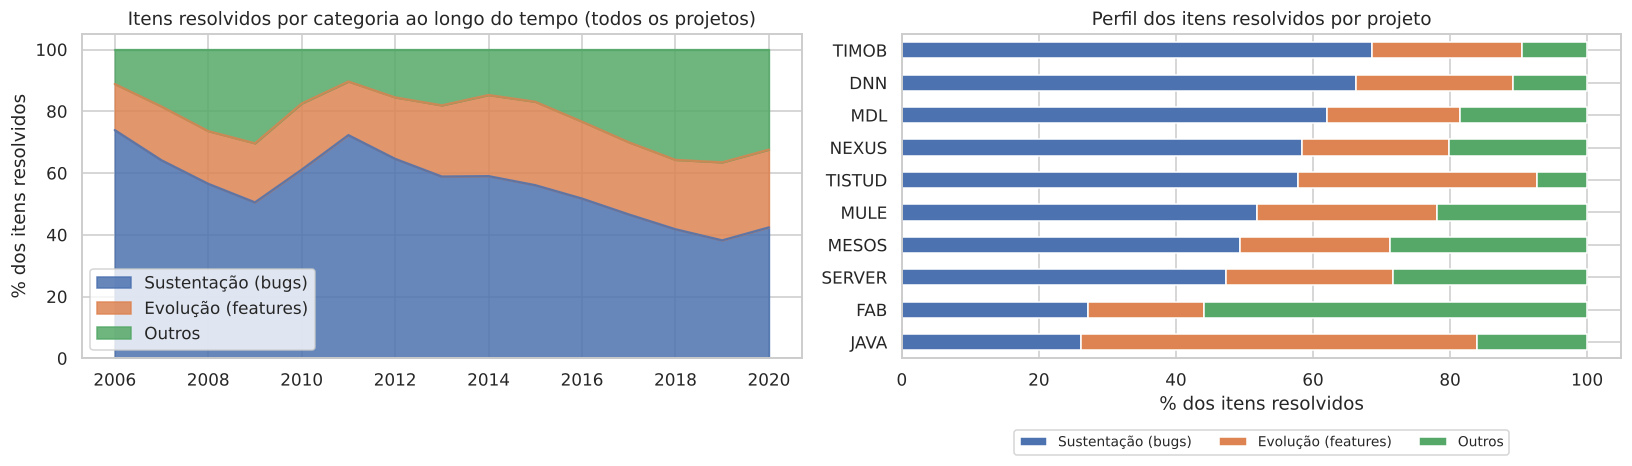

Em média, 53.3% dos itens resolvidos foram correções de bugs.


In [26]:
cap = pd.read_csv("bases/base_capacidade_mensal.csv", parse_dates=["Mes"])
cap["Ano"] = cap.Mes.dt.year
anual = cap.groupby("Ano")[["Sustentacao_Bugs", "Evolucao_Features", "Outros"]].sum()
anual = anual[anual.sum(axis=1) > 500]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
NOMES_CAP = {"Sustentacao_Bugs": "Sustentação (bugs)", "Evolucao_Features": "Evolução (features)", "Outros": "Outros"}
(anual.div(anual.sum(axis=1), axis=0) * 100).rename(columns=NOMES_CAP).plot.area(ax=ax[0], alpha=.85)
ax[0].set(title="Itens resolvidos por categoria ao longo do tempo (todos os projetos)", ylabel="% dos itens resolvidos", xlabel="")
ax[0].legend(loc="lower left")
por_proj = cap.groupby("Project_Key")[["Sustentacao_Bugs", "Evolucao_Features", "Outros"]].sum()
(por_proj.div(por_proj.sum(axis=1), axis=0) * 100).sort_values("Sustentacao_Bugs").rename(columns=NOMES_CAP).plot.barh(stacked=True, ax=ax[1])
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=9)
ax[1].set(title="Perfil dos itens resolvidos por projeto", xlabel="% dos itens resolvidos", ylabel="")
salvar("09_capacidade_sustentacao_evolucao")
print(f"Em média, {cap.Sustentacao_Bugs.sum() / cap.Itens_Resolvidos.sum():.1%} dos itens resolvidos foram correções de bugs.")

In [27]:
# Um mês com muitos bugs novos é seguido por uma fatia maior de correções entre os itens resolvidos?
# Para não comparar projetos de portes diferentes, cada série é padronizada dentro do projeto (z-score).
c = cap.sort_values(["Project_Key", "Mes"]).copy()
c["z_bugs_abertos"] = c.groupby("Project_Key").Bugs_Abertos_No_Mes.transform(lambda s: (s - s.mean()) / s.std())
linhas = []
for lag in range(0, 4):
    c[f"pct_sust_lag{lag}"] = c.groupby("Project_Key").Pct_Sustentacao.shift(-lag)
    c[f"feat_lag{lag}"] = c.groupby("Project_Key").Evolucao_Features.shift(-lag)
    c[f"z_feat_lag{lag}"] = c.groupby("Project_Key")[f"feat_lag{lag}"].transform(lambda s: (s - s.mean()) / s.std())
    r1, p1 = stats.spearmanr(c.z_bugs_abertos, c[f"pct_sust_lag{lag}"], nan_policy="omit")
    r2, p2 = stats.spearmanr(c.z_bugs_abertos, c[f"z_feat_lag{lag}"], nan_policy="omit")
    linhas.append((f"t+{lag}", r1, p1, r2, p2))
display(pd.DataFrame(linhas, columns=["mês", "rho_%sustentação", "p", "rho_features_entregues", "p "]).round(4))

# No nível de release: muitos bugs na release R → a release seguinte (R+1) entrega mais correção e menos feature?
r = rel.sort_values(["Project_Key", "Release_Date"]).copy()
r = r[r.Tipo_Release != "pre-release"]
for col in ["Pct_Correcoes", "Pct_Features", "Qtd_Features"]:
    r[f"prox_{col}"] = r.groupby("Project_Key")[col].shift(-1)
res = [(col, *stats.spearmanr(r.Bugs_Por_Item_Entregue, r[f"prox_{col}"], nan_policy="omit"))
       for col in ["Pct_Correcoes", "Pct_Features", "Qtd_Features"]]
print("Bugs por item entregue na release R × composição da release seguinte (R+1):")
display(pd.DataFrame(res, columns=["variável em R+1", "rho_spearman", "p_valor"]).round(4))

,mês,rho_%sustentação,p,rho_features_entregues,p
0,t+0,0.0793,0.0056,0.4472,0.0
1,t+1,0.0525,0.0684,0.3415,0.0
2,t+2,0.0066,0.8205,0.3039,0.0
3,t+3,-0.0261,0.3683,0.2831,0.0


Bugs por item entregue na release R × composição da release seguinte (R+1):


,variável em R+1,rho_spearman,p_valor
0,Pct_Correcoes,0.0886,0.0035
1,Pct_Features,0.0014,0.9620
2,Qtd_Features,0.0525,0.0843


## 6.3 Risco de pessoa-chave e sobrecarga (P5)
- **Carga do responsável:** itens em aberto atribuídos à mesma pessoa no dia em que o bug foi aberto.
- **Concentração (*bus factor*):** quantas pessoas resolvem metade dos bugs de cada projeto. Responde com dado real ao cenário "saída de uma pessoa-chave".

,responsaveis_distintos,pessoas_que_resolvem_50pct,pct_do_maior_responsavel
Project_Key,,,
JAVA,20,2,47.8
DNN,19,3,34.1
TISTUD,41,3,22.3
NEXUS,64,5,12.5
MULE,99,9,9.2
TIMOB,114,10,11.1
MDL,420,13,12.9
FAB,243,13,8.8
MESOS,171,14,7.8


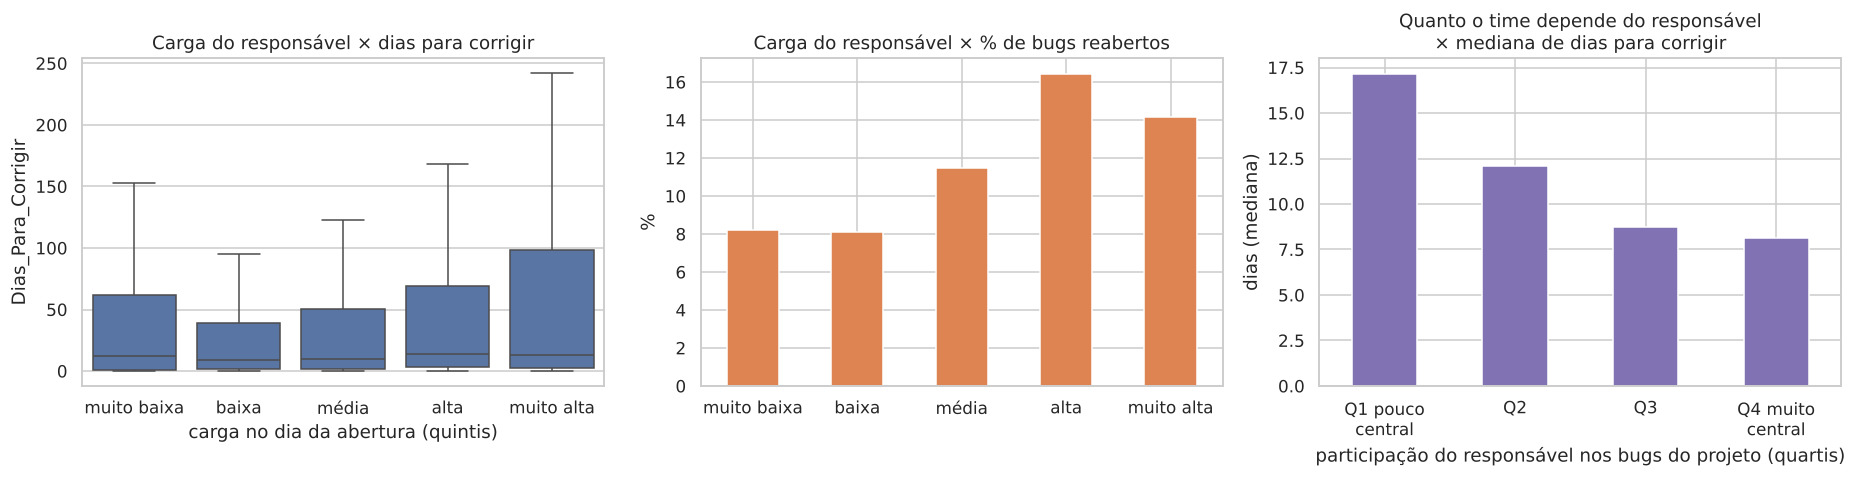

Kruskal-Wallis dias × faixa de carga: H = 285.0, p = 1.91e-60
Qui-quadrado reabertura × faixa de carga: chi² = 551.7, p = 4.34e-118
Spearman carga × dias, dentro de cada projeto:


Project_Key,DNN,FAB,JAVA,MDL,MESOS,MULE,NEXUS,SERVER,TIMOB,TISTUD
rho,0.108,-0.112,0.189,-0.146,-0.026,0.013,-0.1,-0.078,0.368,0.105


Kruskal-Wallis dias × centralidade do responsável: H = 894.0, p = 1.73e-193


In [28]:
def bus_factor(s, alvo=0.5):
    p = s.value_counts(normalize=True).cumsum()
    return int((p < alvo).sum() + 1)

bf = bugs.dropna(subset=["Carga_Responsavel"]).copy()
conc_proj = bugs.dropna(subset=["Responsavel_ID"]).groupby("Project_Key").agg(
    responsaveis_distintos=("Responsavel_ID", "nunique"),
    pessoas_que_resolvem_50pct=("Responsavel_ID", bus_factor),
    pct_do_maior_responsavel=("Responsavel_ID", lambda s: s.value_counts(normalize=True).iloc[0] * 100))
display(conc_proj.round(1).sort_values("pessoas_que_resolvem_50pct"))

bf["Faixa_Carga"] = pd.qcut(bf.Carga_Responsavel, 5, labels=["muito baixa", "baixa", "média", "alta", "muito alta"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=bf, x="Faixa_Carga", y="Dias_Para_Corrigir", showfliers=False, ax=ax[0])
ax[0].set(title="Carga do responsável × dias para corrigir", xlabel="carga no dia da abertura (quintis)")
(bf.groupby("Faixa_Carga").Foi_Reaberto.mean() * 100).plot.bar(ax=ax[1], color="#DD8452", rot=0)
ax[1].set(title="Carga do responsável × % de bugs reabertos", xlabel="", ylabel="%")
bf["Faixa_Centralidade"] = pd.qcut(bf.Participacao_Responsavel_No_Projeto, 4,
                                   labels=["Q1 pouco\ncentral", "Q2", "Q3", "Q4 muito\ncentral"])
conc = bf.groupby("Faixa_Centralidade").Dias_Para_Corrigir.median()
conc.plot.bar(ax=ax[2], color="#8172B3", rot=0)
ax[2].set(title="Quanto o time depende do responsável\n× mediana de dias para corrigir",
          xlabel="participação do responsável nos bugs do projeto (quartis)", ylabel="dias (mediana)")
salvar("10_carga_concentracao")

h, p = stats.kruskal(*[g.Dias_Para_Corrigir for _, g in bf.groupby("Faixa_Carga")])
print(f"Kruskal-Wallis dias × faixa de carga: H = {h:.1f}, p = {p:.2e}")
chi2, p2, _, _ = stats.chi2_contingency(pd.crosstab(bf.Faixa_Carga, bf.Foi_Reaberto))
print(f"Qui-quadrado reabertura × faixa de carga: chi² = {chi2:.1f}, p = {p2:.2e}")
rho = bf.groupby("Project_Key").apply(lambda g: stats.spearmanr(g.Carga_Responsavel, g.Dias_Para_Corrigir)[0])
print("Spearman carga × dias, dentro de cada projeto:"); display(rho.round(3).to_frame("rho").T)
h, p = stats.kruskal(*[g.Dias_Para_Corrigir for _, g in bf.groupby("Faixa_Centralidade")])
print(f"Kruskal-Wallis dias × centralidade do responsável: H = {h:.1f}, p = {p:.2e}")

## 6.4 Retrabalho: o que faz um bug ser reaberto? (P7)
**Momento da previsão:** quando o bug é marcado como resolvido. Por isso o tempo que levou para corrigir pode entrar como variável. A pergunta prática é se dá para sinalizar, no fechamento, quais correções merecem uma validação extra.

% de bugs reabertos por projeto (depende muito do fluxo de cada time):


Project_Key,FAB,SERVER,MESOS,JAVA,NEXUS,MDL,MULE,TIMOB,DNN,TISTUD
% reabertos,0.0,1.2,4.0,5.2,5.8,11.6,13.9,24.7,27.6,34.2


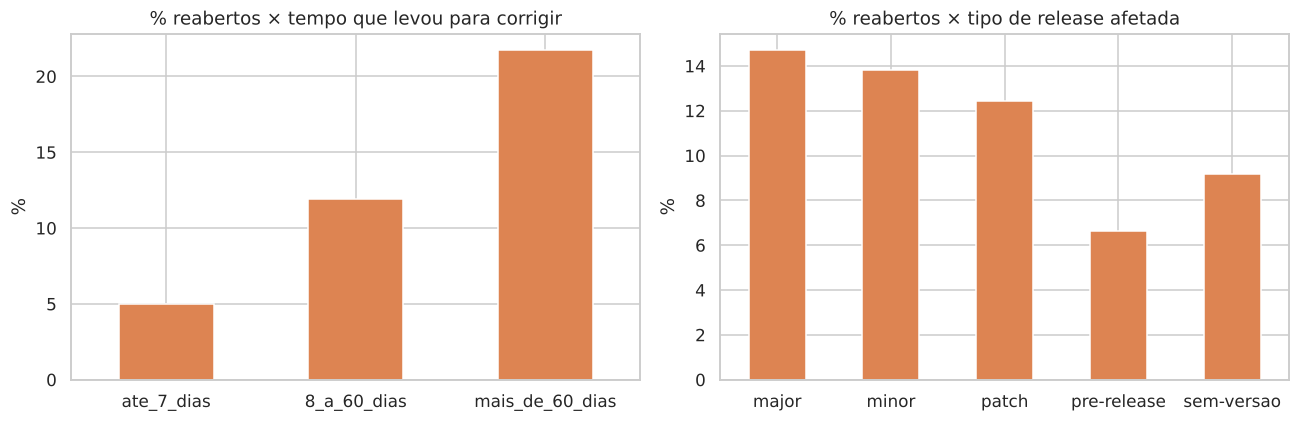

Taxa de reabertura: treino 14.5% | teste 4.2% (a queda vem de mudanças de fluxo: vários times, como SERVER, MESOS e NEXUS, deixaram de usar o status Reopened; os projetos que mais reabrem perderam peso; e bugs recentes tiveram menos tempo para serem reabertos)


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.042,0.042,0.000,0.000,0.489
Regressão Logística,0.818,0.129,0.042,0.671,0.114,0.529
Random Forest,0.839,0.157,0.042,0.671,0.135,0.556
XGBoost,0.801,0.132,0.042,0.645,0.107,0.521


In [29]:
print("% de bugs reabertos por projeto (depende muito do fluxo de cada time):")
display((bugs.groupby("Project_Key").Foi_Reaberto.mean() * 100).round(1).sort_values().to_frame("% reabertos").T)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bugs["Faixa_Correcao_cat"] = pd.Categorical(bugs.Faixa_Correcao, CLASSES, ordered=True)
(bugs.groupby("Faixa_Correcao_cat").Foi_Reaberto.mean() * 100).plot.bar(ax=ax[0], rot=0, color="#DD8452")
ax[0].set(title="% reabertos × tempo que levou para corrigir", xlabel="", ylabel="%")
(bugs.groupby("Tipo_Release_Afetada").Foi_Reaberto.mean() * 100).reindex(ORDEM_TIPO + ["sem-versao"]).plot.bar(ax=ax[1], rot=0, color="#DD8452")
ax[1].set(title="% reabertos × tipo de release afetada", xlabel="", ylabel="%")
salvar("11_reabertura_descritivo")

NUM_RE = NUM_B + ["Dias_Para_Corrigir", "Carga_Responsavel", "Participacao_Responsavel_No_Projeto", "Tem_Responsavel"]
print(f"Taxa de reabertura: treino {tr_b.Foi_Reaberto.mean():.1%} | teste {te_b.Foi_Reaberto.mean():.1%} "
      "(a queda vem de mudanças de fluxo: vários times, como SERVER, MESOS e NEXUS, deixaram de usar o status Reopened; os projetos que mais reabrem perderam peso; e bugs recentes tiveram menos tempo para serem reabertos)")
res_re, fit_re = avaliar_bin(tr_b[CAT_B + NUM_RE], tr_b.Foi_Reaberto, te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, CAT_B, NUM_RE)
res_re

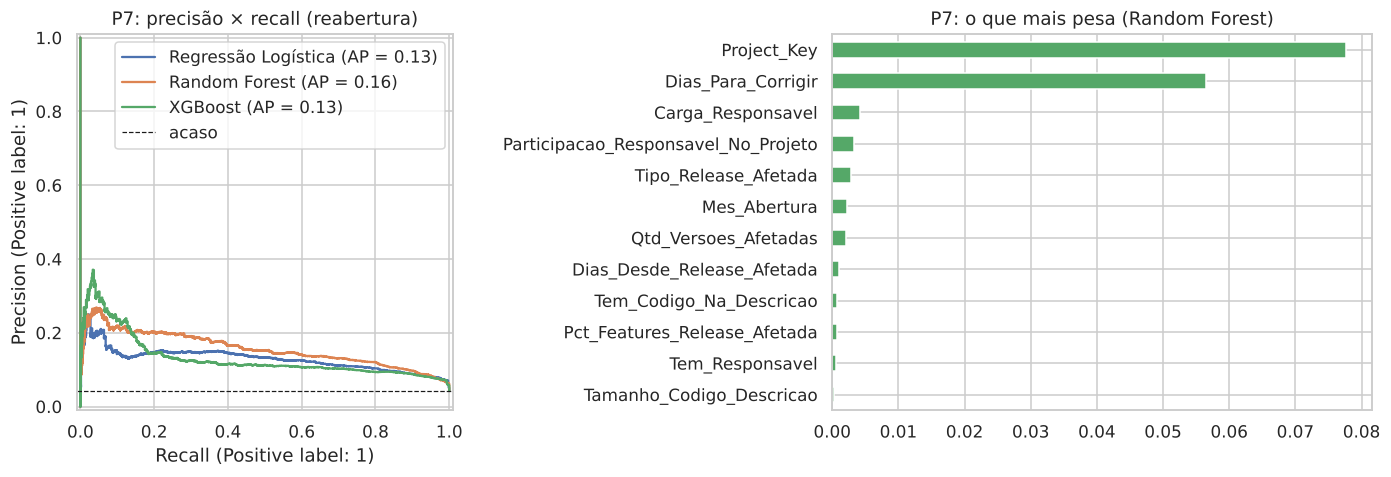

In [30]:
melhor_re = res_re.drop(index="Baseline (classe mais frequente)")["PR_AUC (precisão média)"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    PrecisionRecallDisplay.from_estimator(fit_re[nome], te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, ax=ax[0], name=nome)
ax[0].axhline(te_b.Foi_Reaberto.mean(), color="k", ls="--", lw=.8, label="acaso")
ax[0].set_title("P7: precisão × recall (reabertura)"); ax[0].legend(loc="upper right")
amostra = te_b.sample(min(5000, len(te_b)), random_state=RANDOM_STATE)
pi = permutation_importance(fit_re[melhor_re], amostra[CAT_B + NUM_RE], amostra.Foi_Reaberto,
                            scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=CAT_B + NUM_RE).sort_values().tail(12).plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"P7: o que mais pesa ({melhor_re})")
salvar("12_reabertura_modelo")

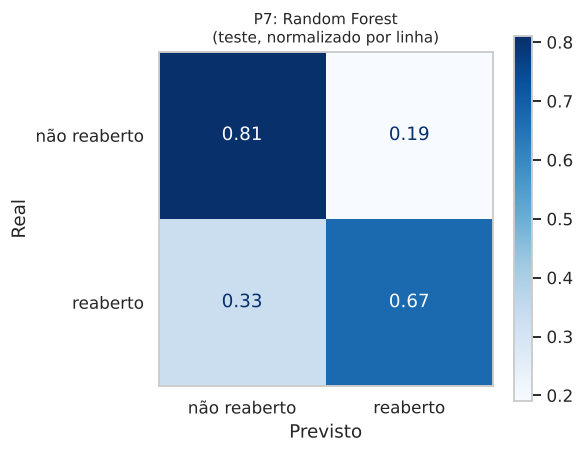

In [31]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_re[melhor_re], te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, display_labels=["não reaberto", "reaberto"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P7: " + melhor_re + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("12b_reabertura_matriz_confusao")

## 6.5 Sinais de criticidade: quais bugs vão "escalar"? (P8)
A base não registra clientes afetados nem impacto financeiro. Usamos dois **eventos observáveis** que sinalizam criticidade, sem afirmar que medem o impacto real:
- **Duplicatas:** outros registros foram marcados como duplicata do bug, ou seja, o mesmo problema foi reportado mais de uma vez.
- **Escalada de prioridade:** o bug ficou mais grave depois de aberto.

`Alta_Criticidade = 1` quando há pelo menos uma das duas. **Momento da previsão:** a abertura do bug, com as mesmas variáveis do Modelo 1.

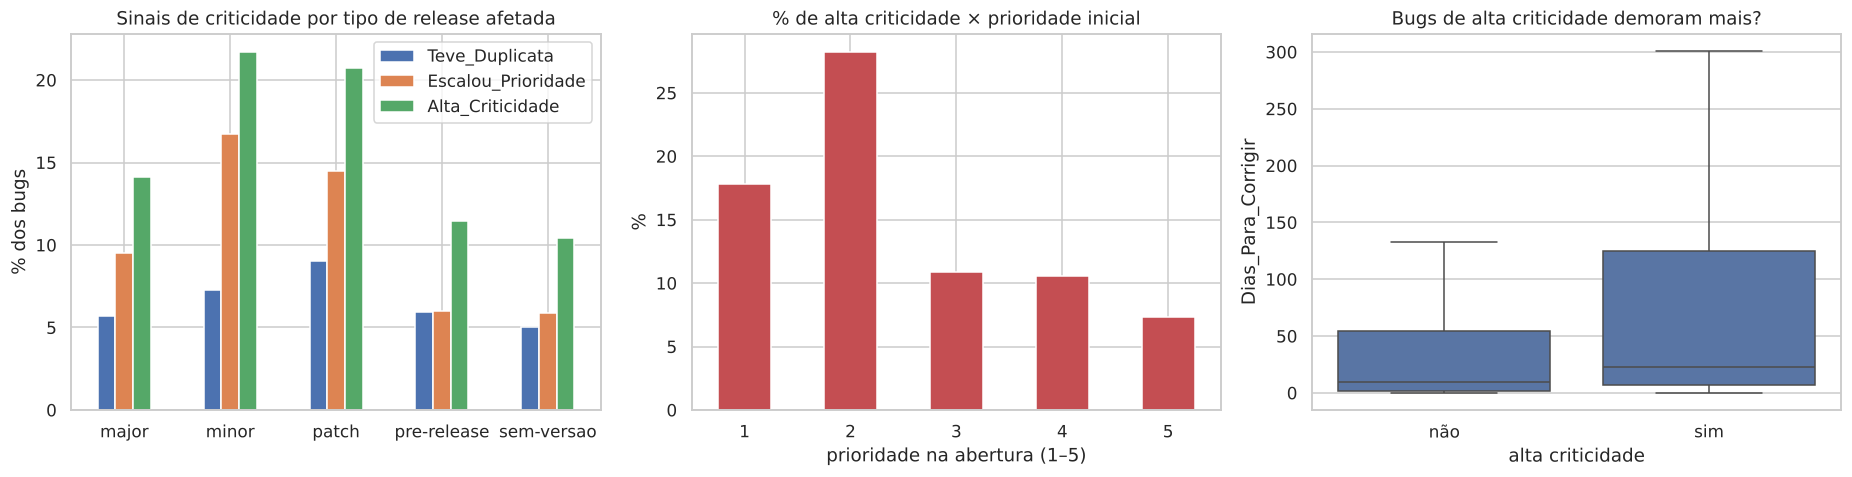

Qui-quadrado alta criticidade × tipo de release afetada: chi² = 1054.3, p = 6.15e-227
Mann-Whitney dias (alta criticidade × demais): p = 1.36e-262; medianas = 23.1 × 9.9 dias


,AUC,PR_AUC (precisão média),taxa_base_positivos,recall_positivos,precisao_positivos,F1_macro
modelo,,,,,,
Baseline (classe mais frequente),0.500,0.148,0.148,0.000,0.000,0.460
Regressão Logística,0.670,0.265,0.148,0.548,0.246,0.566
Random Forest,0.685,0.289,0.148,0.450,0.301,0.608
XGBoost,0.675,0.281,0.148,0.476,0.288,0.601


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
imp_tipo = bugs.groupby("Tipo_Release_Afetada")[["Escalou_Prioridade", "Alta_Criticidade"]].mean().reindex(ORDEM_TIPO + ["sem-versao"]) * 100
imp_tipo["Teve_Duplicata"] = bugs.groupby("Tipo_Release_Afetada").Qtd_Duplicados.apply(lambda s: (s > 0).mean() * 100)
imp_tipo[["Teve_Duplicata", "Escalou_Prioridade", "Alta_Criticidade"]].plot.bar(ax=ax[0], rot=0)
ax[0].set(title="Sinais de criticidade por tipo de release afetada", ylabel="% dos bugs", xlabel="")
(bugs.groupby("Prioridade_Nivel").Alta_Criticidade.mean() * 100).plot.bar(ax=ax[1], rot=0, color="#C44E52")
ax[1].set(title="% de alta criticidade × prioridade inicial", xlabel="prioridade na abertura (1–5)", ylabel="%")
sns.boxplot(data=bugs, x="Alta_Criticidade", y="Dias_Para_Corrigir", showfliers=False, ax=ax[2])
ax[2].set(title="Bugs de alta criticidade demoram mais?", xticklabels=["não", "sim"], xlabel="alta criticidade")
salvar("13_impacto_descritivo")

chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(bugs.Tipo_Release_Afetada, bugs.Alta_Criticidade))
print(f"Qui-quadrado alta criticidade × tipo de release afetada: chi² = {chi2:.1f}, p = {p:.2e}")
u, p = stats.mannwhitneyu(bugs.loc[bugs.Alta_Criticidade == 1, "Dias_Para_Corrigir"], bugs.loc[bugs.Alta_Criticidade == 0, "Dias_Para_Corrigir"])
print(f"Mann-Whitney dias (alta criticidade × demais): p = {p:.2e}; medianas = "
      f"{bugs.loc[bugs.Alta_Criticidade == 1, 'Dias_Para_Corrigir'].median():.1f} × {bugs.loc[bugs.Alta_Criticidade == 0, 'Dias_Para_Corrigir'].median():.1f} dias")

res_im, fit_im = avaliar_bin(tr_b[CAT_B + NUM_B], tr_b.Alta_Criticidade, te_b[CAT_B + NUM_B], te_b.Alta_Criticidade, CAT_B, NUM_B)
res_im

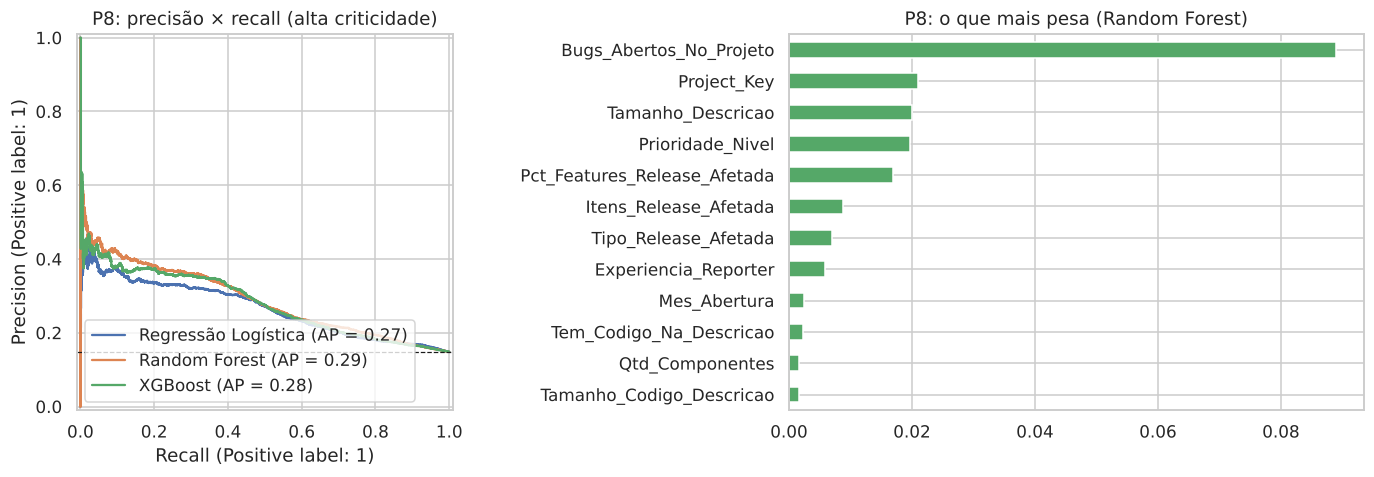

In [33]:
melhor_im = res_im.drop(index="Baseline (classe mais frequente)")["PR_AUC (precisão média)"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nome in ["Regressão Logística", "Random Forest", "XGBoost"]:
    PrecisionRecallDisplay.from_estimator(fit_im[nome], te_b[CAT_B + NUM_B], te_b.Alta_Criticidade, ax=ax[0], name=nome)
ax[0].axhline(te_b.Alta_Criticidade.mean(), color="k", ls="--", lw=.8)
ax[0].set_title("P8: precisão × recall (alta criticidade)")
amostra = te_b.sample(min(5000, len(te_b)), random_state=RANDOM_STATE)
pi = permutation_importance(fit_im[melhor_im], amostra[CAT_B + NUM_B], amostra.Alta_Criticidade,
                            scoring="average_precision", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
pd.Series(pi.importances_mean, index=CAT_B + NUM_B).sort_values().tail(12).plot.barh(ax=ax[1], color="#55A868")
ax[1].set_title(f"P8: o que mais pesa ({melhor_im})")
salvar("14_impacto_modelo")

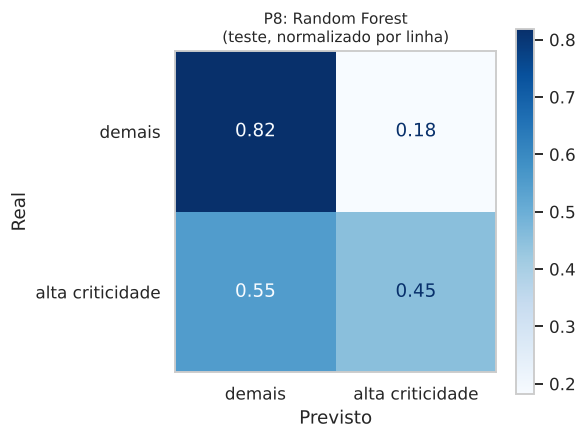

In [34]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_estimator(fit_im[melhor_im], te_b[CAT_B + NUM_B], te_b.Alta_Criticidade, display_labels=["demais", "alta criticidade"], normalize="true",
                                      values_format=".2f", cmap="Blues", ax=ax)
ax.set_title("P8: " + melhor_im + "\n(teste, normalizado por linha)", fontsize=10); ax.grid(False); ax.set(xlabel="Previsto", ylabel="Real")
salvar("14b_impacto_matriz_confusao")

# 7. Robustez e validação das escolhas metodológicas
Esta seção testa as principais escolhas do trabalho contra alternativas que uma banca poderia sugerir:
1. **Poisson × Binomial Negativa** para a contagem de bugs pós-release;
2. **Análise de sobrevivência** (Kaplan-Meier e regressão de Cox) para o tempo de correção, incluindo os bugs que **não** foram corrigidos (observações censuradas);
3. **Ajuste de hiperparâmetros** com validação temporal;
4. **Intervalos de confiança por bootstrap** para as métricas e para a diferença entre modelos;
5. **Calibração** das probabilidades previstas.

## 7.1 Poisson × Binomial Negativa
A regressão de Poisson supõe variância igual à média. Se os dados tiverem **sobredispersão** (variância muito maior que a média), a Poisson subestima os erros-padrão e "acha" efeitos significativos demais; a Binomial Negativa corrige isso.

In [35]:
import statsmodels.api as sm
formula_nb = ("Bugs_Pos_Release ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
              " + log_itens + log_componentes + log_dias_ant + C(Project_Key)")
pois = smf.glm(formula_nb, data=d, family=sm.families.Poisson()).fit()
disp = pois.pearson_chi2 / pois.df_resid
print(f"Média de bugs pós-release = {d.Bugs_Pos_Release.mean():.1f} | variância = {d.Bugs_Pos_Release.var():.1f}")
print(f"Dispersão de Pearson da Poisson = {disp:.1f} (≈ 1 seria adequado à Poisson)")
print(f"AIC Poisson = {pois.aic:,.0f} | AIC Binomial Negativa = {nb.aic:,.0f} (menor é melhor)")
print(f"Parâmetro de sobredispersão (alpha) da Binomial Negativa = {nb.params['alpha']:.2f} "
      f"(IC95%: {nb.conf_int().loc['alpha', 0]:.2f} a {nb.conf_int().loc['alpha', 1]:.2f})")

Média de bugs pós-release = 37.2 | variância = 4173.5
Dispersão de Pearson da Poisson = 36.3 (≈ 1 seria adequado à Poisson)
AIC Poisson = 39,376 | AIC Binomial Negativa = 10,363 (menor é melhor)
Parâmetro de sobredispersão (alpha) da Binomial Negativa = 1.10 (IC95%: 1.02 a 1.19)


## 7.2 Tempo de correção como análise de sobrevivência
Nas seções 3 e 4, o tempo de correção foi analisado **apenas nos bugs corrigidos**. Bugs que continuam abertos ou que foram encerrados sem correção ficam de fora, e isso pode distorcer as estimativas (viés de seleção). A análise de sobrevivência usa **todos os bugs** do mesmo período: os não corrigidos entram como **censurados**, isto é, sabe-se apenas que não foram corrigidos até a data observada.
- **Kaplan-Meier:** proporção de bugs ainda não corrigidos ao longo do tempo, por grupo; teste log-rank para comparar grupos.
- **Regressão de Cox:** efeito de cada variável na "velocidade" de correção. *Hazard ratio* (HR) > 1 indica correção mais rápida; < 1, mais lenta. Estratificada por projeto.

Bugs na base de sobrevivência: 105,637


,% dos bugs
Situacao_Final,
corrigido,52.7
encerrado_sem_correcao,35.1
aberto_na_coleta,12.2


Mediana do tempo de correção – só bugs corrigidos: 11.8 dias | Kaplan-Meier com censura: 131.3 dias


Log-rank Tipo_Release_Afetada: chi² = 2,938, p = 0.0e+00


,Tipo_Release_Afetada,n,mediana_KM_dias
0,major,7619,44.3
1,minor,26053,140.6
2,patch,35950,496.7
3,pre-release,2916,14.8
4,sem-versao,33099,56.9


Log-rank Prioridade_Nivel: chi² = 4,118, p = 0.0e+00


,Prioridade_Nivel,n,mediana_KM_dias
0,1,3472,NaN
1,2,39207,531.2
2,3,45412,55.2
3,4,15345,74.5
4,5,2201,8.4


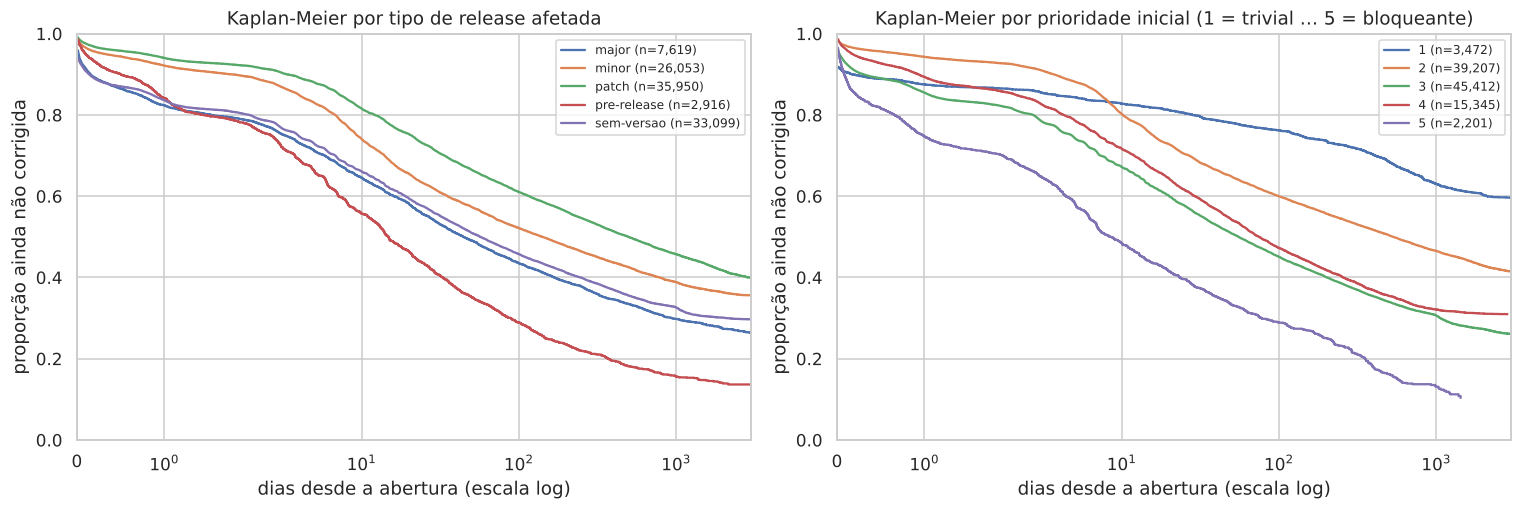

In [36]:
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg

surv = pd.read_csv("bases/base_bugs_sobrevivencia.csv", parse_dates=["Creation_Date"])
surv["Tempo_Dias"] = surv.Tempo_Dias.clip(lower=0.01)
print(f"Bugs na base de sobrevivência: {len(surv):,}")
display(surv.Situacao_Final.value_counts(normalize=True).mul(100).round(1).to_frame("% dos bugs"))

med_sel = bugs.Dias_Para_Corrigir.median()
km_all = SurvfuncRight(surv.Tempo_Dias, surv.Evento_Corrigido)
print(f"Mediana do tempo de correção – só bugs corrigidos: {med_sel:.1f} dias | "
      f"Kaplan-Meier com censura: {km_all.quantile(0.5):.1f} dias")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for grupo, titulo, a, ordem in [("Tipo_Release_Afetada", "por tipo de release afetada", ax[0], ORDEM_TIPO + ["sem-versao"]),
                                ("Prioridade_Nivel", "por prioridade inicial (1 = trivial … 5 = bloqueante)", ax[1], [1, 2, 3, 4, 5])]:
    linhas = []
    for g in ordem:
        s = surv[surv[grupo] == g]
        if len(s) < 50:
            continue
        km = SurvfuncRight(s.Tempo_Dias, s.Evento_Corrigido)
        a.step(km.surv_times, km.surv_prob, where="post", label=f"{g} (n={len(s):,})")
        linhas.append((g, len(s), km.quantile(0.5)))
    a.set(xscale="symlog", xlim=(0, 3000), ylim=(0, 1), xlabel="dias desde a abertura (escala log)",
          ylabel="proporção ainda não corrigida", title=f"Kaplan-Meier {titulo}")
    a.legend(fontsize=8)
    stat, p = survdiff(surv.Tempo_Dias, surv.Evento_Corrigido, surv[grupo])
    print(f"Log-rank {grupo}: chi² = {stat:,.0f}, p = {p:.1e}")
    display(pd.DataFrame(linhas, columns=[grupo, "n", "mediana_KM_dias"]).round(1))
salvar("18_sobrevivencia_kaplan_meier")

In [37]:
# Sensibilidade: bugs encerrados sem correção ("Won't Fix", "Duplicate" etc.) nunca serão corrigidos.
# Tratá-los como censurados aumenta o tempo estimado; excluí-los dá o cenário oposto.
cen = []
for rotulo, df_ in [("só bugs corrigidos (seções 3 e 4)", None),
                    ("Kaplan-Meier, encerrados sem correção excluídos", surv[surv.Situacao_Final != "encerrado_sem_correcao"]),
                    ("Kaplan-Meier, encerrados sem correção censurados", surv)]:
    linha = {"cenário": rotulo}
    for g in ORDEM_TIPO + ["sem-versao"]:
        if df_ is None:
            linha[g] = bugs.loc[bugs.Tipo_Release_Afetada == g, "Dias_Para_Corrigir"].median()
        else:
            s_ = df_[df_.Tipo_Release_Afetada == g]
            linha[g] = SurvfuncRight(s_.Tempo_Dias, s_.Evento_Corrigido).quantile(0.5)
    cen.append(linha)
print("Mediana de dias para corrigir, por tipo de release afetada, em cada cenário:")
pd.DataFrame(cen).set_index("cenário").round(1)

Mediana de dias para corrigir, por tipo de release afetada, em cada cenário:


,major,minor,patch,pre-release,sem-versao
cenário,,,,,
só bugs corrigidos (seções 3 e 4),7.0,12.9,20.4,6.6,7.4
"Kaplan-Meier, encerrados sem correção excluídos",10.0,28.4,43.9,7.0,15.3
"Kaplan-Meier, encerrados sem correção censurados",44.3,140.6,496.7,14.8,56.9


In [38]:
# Regressão de Cox (mesmas variáveis do Modelo 1), estratificada por projeto, treino até 30 jun. 2016
NUM_COX = ["Prioridade_Nivel", "Tamanho_Titulo", "Tamanho_Descricao", "Tem_Codigo_Na_Descricao", "Qtd_Componentes",
           "Qtd_Versoes_Afetadas", "Bugs_Abertos_No_Projeto", "Experiencia_Reporter", "Tem_Story_Point"]
def matriz_cox(df):
    X = pd.DataFrame(index=df.index)
    for c in NUM_COX:
        X[c] = np.log1p(df[c].clip(lower=0)) if c not in ("Prioridade_Nivel", "Tem_Codigo_Na_Descricao", "Tem_Story_Point") else df[c]
    for t in ["major", "patch", "pre-release", "sem-versao"]:          # referência: minor
        X[f"release_{t}"] = (df.Tipo_Release_Afetada == t).astype(int)
    return X
tr_s7 = surv[surv.Creation_Date < corte_b]
te_s7 = surv[surv.Creation_Date >= corte_b]
Xc = matriz_cox(tr_s7)
cox = PHReg(tr_s7.Tempo_Dias.values, Xc.values, status=tr_s7.Evento_Corrigido.values,
            strata=tr_s7.Project_Key.values).fit()
hr = pd.DataFrame({"hazard_ratio": np.exp(cox.params), "IC95_inf": np.exp(cox.conf_int()[:, 0]),
                   "IC95_sup": np.exp(cox.conf_int()[:, 1]), "p_valor": cox.pvalues}, index=Xc.columns)
display(hr.round(3))

def c_index(tempo, evento, risco, n=4000, seed=RANDOM_STATE):
    # índice de concordância de Harrell (amostra de até n bugs): maior risco previsto -> corrigido antes
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(tempo), size=min(n, len(tempo)), replace=False)
    t, e, r = np.asarray(tempo)[idx], np.asarray(evento)[idx], np.asarray(risco)[idx]
    comparavel = (t[:, None] < t[None, :]) & (e[:, None] == 1)
    conc = (r[:, None] > r[None, :]) & comparavel
    emp = (r[:, None] == r[None, :]) & comparavel
    return (conc.sum() + 0.5 * emp.sum()) / comparavel.sum()

risco_te = matriz_cox(te_s7).values @ cox.params
print(f"Índice C (concordância) no teste, bugs a partir de jul. 2016: {c_index(te_s7.Tempo_Dias, te_s7.Evento_Corrigido, risco_te):.3f} "
      "(0,5 = acaso; 1 = ordenação perfeita)")

,hazard_ratio,IC95_inf,IC95_sup,p_valor
Prioridade_Nivel,1.316,1.298,1.334,0.0
Tamanho_Titulo,1.125,1.095,1.155,0.0
Tamanho_Descricao,0.900,0.893,0.906,0.0
Tem_Codigo_Na_Descricao,1.073,1.041,1.105,0.0
Qtd_Componentes,0.882,0.847,0.919,0.0
Qtd_Versoes_Afetadas,1.322,1.261,1.386,0.0
Bugs_Abertos_No_Projeto,0.947,0.935,0.960,0.0
Experiencia_Reporter,1.106,1.101,1.112,0.0
Tem_Story_Point,1.730,1.672,1.789,0.0
release_major,1.280,1.233,1.328,0.0


Índice C (concordância) no teste, bugs a partir de jul. 2016: 0.612 (0,5 = acaso; 1 = ordenação perfeita)


## 7.3 Ajuste de hiperparâmetros com validação temporal
Os modelos das seções 4 e 5 usam configurações fixas e razoáveis. Aqui buscamos configurações melhores com **busca aleatória** e **validação cruzada temporal** (`TimeSeriesSplit`, três janelas) **somente no período de treino**. O teste continua intocado. No Google Colab esta etapa é pulada por padrão, porque leva alguns minutos em máquinas com poucos núcleos; a tabela de resultados fica salva no notebook do repositório.

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

def busca(nome, base_modelo, grade, Xtr, ytr, cat, num, scoring, n_iter, fit_params=None):
    pipe = Pipeline([("prep", preproc(cat, num, escalar=False)), ("modelo", base_modelo)])
    rs = RandomizedSearchCV(pipe, grade, n_iter=n_iter, cv=TimeSeriesSplit(n_splits=3), scoring=scoring,
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    rs.fit(Xtr, ytr, **(fit_params or {}))
    return rs

grade_rf = {"modelo__n_estimators": randint(200, 600), "modelo__max_depth": [None, 6, 10, 16],
            "modelo__min_samples_leaf": randint(2, 30), "modelo__max_features": ["sqrt", 0.3, 0.5]}
grade_xgb = {"modelo__n_estimators": randint(150, 600), "modelo__max_depth": randint(2, 8),
             "modelo__learning_rate": loguniform(0.01, 0.2), "modelo__subsample": uniform(0.6, 0.4),
             "modelo__colsample_bytree": uniform(0.5, 0.5), "modelo__min_child_weight": randint(1, 10)}

import sys
# No Google Colab (máquina com poucos núcleos) a busca é pulada para economizar tempo;
# os resultados abaixo ficam salvos no notebook do repositório. Mude para True para rodar mesmo assim.
EXECUTAR_AJUSTE = "google.colab" not in sys.modules
def rodar_ajuste():
    linhas = []
    # Modelo 1 (tempo de correção, 3 classes)
    w_b = ytr_b.map(1 / ytr_b.value_counts(normalize=True)).values
    for nome, m, g, fp in [("Random Forest", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), grade_rf, None),
                           ("XGBoost", XGBClassifier(eval_metric="mlogloss", random_state=RANDOM_STATE, n_jobs=-1), grade_xgb, {"modelo__sample_weight": w_b})]:
        rs = busca(nome, m, g, Xtr_b, ytr_b, CAT_B, NUM_B, "f1_macro", n_iter=8, fit_params=fp)
        pred = rs.predict(Xte_b)
        linhas.append(("Modelo 1 – tempo de correção", nome, "F1 macro", res_b.loc[nome, "F1_macro"], f1_score(yte_b, pred, average="macro")))
    # Modelo 2 (risco de release, binário) – treino ordenado no tempo
    tr_r_ord = tr_r.sort_values("Release_Date")
    for nome, m, g in [("Random Forest", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1), grade_rf),
                       ("XGBoost", XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1), grade_xgb)]:
        rs = busca(nome, m, g, tr_r_ord[CAT_R + NUM_R], tr_r_ord.Alto_Risco, CAT_R, NUM_R, "roc_auc", n_iter=20)
        proba = rs.predict_proba(te_r[CAT_R + NUM_R])[:, 1]
        linhas.append(("Modelo 2 – risco da release", nome, "AUC", res_r.loc[nome, "AUC"], roc_auc_score(te_r.Alto_Risco, proba)))
    tun = pd.DataFrame(linhas, columns=["modelo", "algoritmo", "métrica (teste)", "configuração fixa", "após ajuste"])
    tun["diferença"] = tun["após ajuste"] - tun["configuração fixa"]
    return tun
if EXECUTAR_AJUSTE:
    display(rodar_ajuste().round(3))
else:
    print("Ajuste de hiperparâmetros pulado no Colab (veja a tabela salva no notebook do GitHub).")

,modelo,algoritmo,métrica (teste),configuração fixa,após ajuste,diferença
0,Modelo 1 – tempo de correção,Random Forest,F1 macro,0.427,0.423,-0.004
1,Modelo 1 – tempo de correção,XGBoost,F1 macro,0.428,0.423,-0.005
2,Modelo 2 – risco da release,Random Forest,AUC,0.666,0.653,-0.013
3,Modelo 2 – risco da release,XGBoost,AUC,0.668,0.666,-0.002


## 7.4 Intervalos de confiança por bootstrap
Uma métrica calculada em uma única amostra de teste tem incerteza. Reamostramos o conjunto de teste 500 vezes, com reposição, para obter o **intervalo de confiança de 95%** de cada métrica e da **diferença** entre o melhor modelo e a regressão logística (bootstrap pareado). Se o intervalo da diferença inclui zero, os dois modelos são **estatisticamente equivalentes** naquele teste.

In [40]:
def bootstrap(y, p_a, p_b, metrica, B=500, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y, p_a, p_b = np.asarray(y), np.asarray(p_a), np.asarray(p_b)
    va, vd = [], []
    for _ in range(B):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < len(np.unique(y)):
            continue
        a, b_ = metrica(y[i], p_a[i]), metrica(y[i], p_b[i])
        va.append(a); vd.append(a - b_)
    return np.percentile(va, [2.5, 97.5]), np.percentile(vd, [2.5, 97.5])

casos = [
    ("Modelo 1 – tempo de correção", fit_b, Xte_b, yte_b, "AUC (um contra todos)", lambda y, p: roc_auc_score(y, p, multi_class="ovr"), True, melhor_b),
    ("Modelo 2 – risco da release", fit_r, te_r[CAT_R + NUM_R], te_r.Alto_Risco, "AUC", roc_auc_score, False, melhor_r),
    ("P1 – item não concluído no sprint", fit_s, te_s[CAT_S + NUM_S], te_s.Nao_Concluiu_No_Sprint, "AUC", roc_auc_score, False, melhor_s),
    ("P7 – reabertura", fit_re, te_b[CAT_B + NUM_RE], te_b.Foi_Reaberto, "PR-AUC", average_precision_score, False, melhor_re),
    ("P8 – alta criticidade", fit_im, te_b[CAT_B + NUM_B], te_b.Alta_Criticidade, "PR-AUC", average_precision_score, False, melhor_im),
]
linhas = []
for nome, fits, X, y, mnome, met, multi, melhor in casos:
    pm = fits[melhor].predict_proba(X)
    pl = fits["Regressão Logística"].predict_proba(X)
    if not multi:
        pm, pl = pm[:, 1], pl[:, 1]
    ic, icd = bootstrap(y, pm, pl, met)
    dif = met(y, pm) - met(y, pl)
    linhas.append((nome, melhor, mnome, met(y, pm), f"{ic[0]:.3f} a {ic[1]:.3f}", dif, f"{icd[0]:+.3f} a {icd[1]:+.3f}",
                   "é a própria RL" if melhor == "Regressão Logística" else
                   ("sim" if icd[0] > 0 else ("não (equivalentes)" if icd[0] <= 0 <= icd[1] else "não (RL melhor)"))))
boot = pd.DataFrame(linhas, columns=["modelo", "melhor algoritmo", "métrica", "valor", "IC95%",
                                     "diferença vs. Regressão Logística", "IC95% da diferença", "melhor que a RL?"])
boot.round(3)

,modelo,melhor algoritmo,métrica,valor,IC95%,diferença vs. Regressão Logística,IC95% da diferença,melhor que a RL?
0,Modelo 1 – tempo de correção,XGBoost,AUC (um contra todos),0.626,0.621 a 0.633,0.020,+0.015 a +0.026,sim
1,Modelo 2 – risco da release,XGBoost,AUC,0.668,0.609 a 0.723,0.012,-0.019 a +0.045,não (equivalentes)
2,P1 – item não concluído no sprint,Regressão Logística,AUC,0.684,0.669 a 0.701,0.000,+0.000 a +0.000,é a própria RL
3,P7 – reabertura,Random Forest,PR-AUC,0.157,0.139 a 0.176,0.028,+0.014 a +0.043,sim
4,P8 – alta criticidade,Random Forest,PR-AUC,0.289,0.274 a 0.308,0.023,+0.015 a +0.033,sim


## 7.5 Calibração das probabilidades
Para usar a saída como "probabilidade de risco" em uma decisão de gestão, ela precisa ser **calibrada**: entre os itens com probabilidade prevista de 70%, cerca de 70% devem de fato apresentar o evento. O **escore de Brier** resume o erro das probabilidades (menor é melhor). A ponderação de classes usada no treino tende a "inflar" as probabilidades da classe rara; por isso comparamos também a versão **recalibrada** (regressão isotônica ajustada com validação temporal no treino).

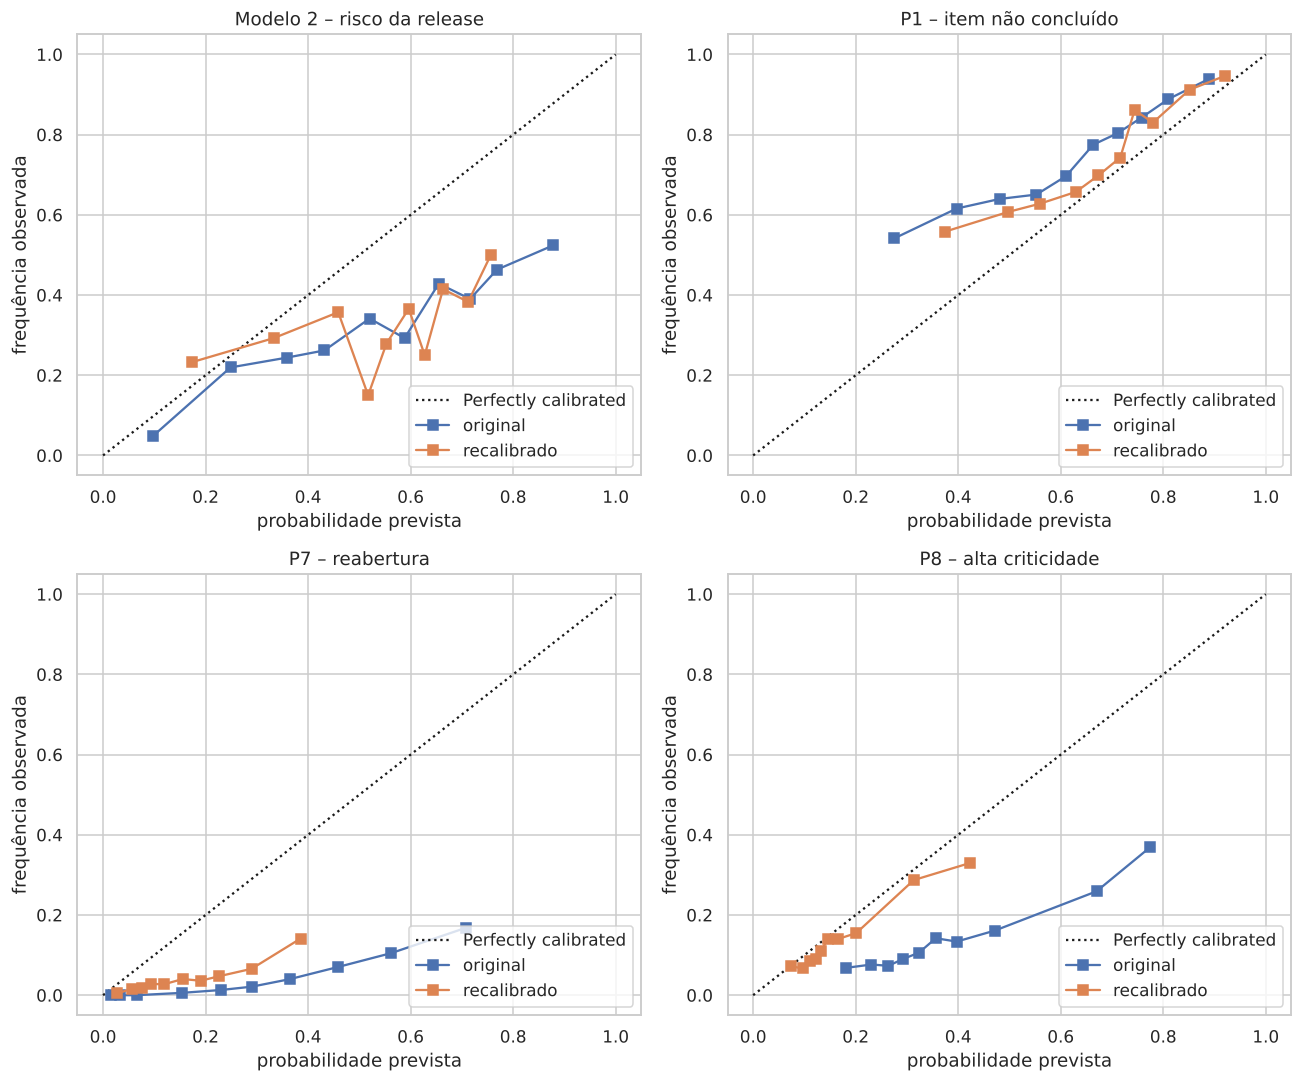

,modelo,Brier original,Brier recalibrado,AUC original,AUC recalibrado
0,Modelo 2 – risco da release,0.253,0.275,0.668,0.587
1,P1 – item não concluído,0.198,0.184,0.684,0.688
2,P7 – reabertura,0.128,0.059,0.839,0.724
3,P8 – alta criticidade,0.188,0.120,0.685,0.676


In [41]:
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import brier_score_loss

casos_bin = [
    ("Modelo 2 – risco da release", fit_r[melhor_r], tr_r.sort_values("Release_Date"), te_r, CAT_R + NUM_R, "Alto_Risco"),
    ("P1 – item não concluído", fit_s[melhor_s], tr_s.sort_values("Start_Date"), te_s, CAT_S + NUM_S, "Nao_Concluiu_No_Sprint"),
    ("P7 – reabertura", fit_re[melhor_re], tr_b, te_b, CAT_B + NUM_RE, "Foi_Reaberto"),
    ("P8 – alta criticidade", fit_im[melhor_im], tr_b, te_b, CAT_B + NUM_B, "Alta_Criticidade"),
]
fig, axs = plt.subplots(2, 2, figsize=(12, 10))
linhas = []
for (nome, modelo, tr_, te_, cols, alvo), ax in zip(casos_bin, axs.ravel()):
    cal = CalibratedClassifierCV(clone(modelo), method="isotonic", cv=TimeSeriesSplit(n_splits=3)).fit(tr_[cols], tr_[alvo])
    p_orig = modelo.predict_proba(te_[cols])[:, 1]
    p_cal = cal.predict_proba(te_[cols])[:, 1]
    CalibrationDisplay.from_predictions(te_[alvo], p_orig, n_bins=10, strategy="quantile", ax=ax, name="original")
    CalibrationDisplay.from_predictions(te_[alvo], p_cal, n_bins=10, strategy="quantile", ax=ax, name="recalibrado")
    ax.set(title=nome, xlabel="probabilidade prevista", ylabel="frequência observada")
    linhas.append((nome, brier_score_loss(te_[alvo], p_orig), brier_score_loss(te_[alvo], p_cal),
                   roc_auc_score(te_[alvo], p_orig), roc_auc_score(te_[alvo], p_cal)))
salvar("19_calibracao")
pd.DataFrame(linhas, columns=["modelo", "Brier original", "Brier recalibrado", "AUC original", "AUC recalibrado"]).round(3)

## 7.6 Disponibilidade temporal das variáveis
Algumas variáveis ficam registradas no **estado final** do item e podem ter sido alteradas depois do momento da previsão. Três versões dos modelos de abertura do bug (Modelo 1 e P8) foram comparadas:
- **estado final:** versões afetadas como estão no fim da coleta;
- **reconstruída (principal):** versões afetadas reconstruídas para o momento da abertura pelo histórico de alterações;
- **estrita:** sem nenhuma variável que não possa ser reconstruída (componentes, story points e todas as variáveis de versão afetada).

Se o desempenho cai pouco na versão estrita, os resultados não dependem de informação posterior à previsão.

In [42]:
display(pd.DataFrame([
    ("Prioridade", "Issue.Priority + Change_Log (priority)", "reconstruída: valor inicial"),
    ("Versões afetadas / release afetada", "Affected_Version + Change_Log (Version)", "reconstruída: na abertura (+1 h)"),
    ("Composição da release", "Fix_Version + Change_Log (Fix Version)", "reconstruída: na data de publicação"),
    ("Sprint do item", "Issue.Sprint_ID + Change_Log (Sprint)", "reconstruído: início e fim de cada sprint"),
    ("Componentes", "Issue_Component", "estado final (sem histórico): só na versão principal"),
    ("Story points", "Issue.Story_Point", "estado final: só na versão principal"),
    ("Responsável", "Issue.Assignee_ID", "estado final: só nas análises da seção 6"),
    ("Tamanho do título e da descrição", "Issue", "estado final (edições raras de texto não são registradas)"),
    ("Carga do projeto e do responsável", "calculada pelas datas de abertura e resolução", "disponível na data da previsão"),
], columns=["variável", "fonte", "tratamento temporal"]))

FINAL = {"Qtd_Versoes_Afetadas": "Qtd_Versoes_Afetadas_Final", "Tipo_Release_Afetada": "Tipo_Release_Afetada_Final",
         "Dias_Desde_Release_Afetada": "Dias_Desde_Release_Afetada_Final", "Itens_Release_Afetada": "Itens_Release_Afetada_Final",
         "Pct_Features_Release_Afetada": "Pct_Features_Release_Afetada_Final"}
NAO_RECONSTR = ["Qtd_Componentes", "Tem_Story_Point"] + list(FINAL)
variantes = {
    "estado final": (CAT_B, NUM_B, FINAL),
    "reconstruída (principal)": (CAT_B, NUM_B, {}),
    "estrita": ([c for c in CAT_B if c not in NAO_RECONSTR], [c for c in NUM_B if c not in NAO_RECONSTR], {}),
}
def preparar(df, ren):
    out = df.copy()
    for novo, antigo in ren.items():
        out[novo] = out[antigo]
    return out
linhas = []
for nome_v, (cat, num, ren) in variantes.items():
    Xtr, Xte = preparar(tr_b, ren)[cat + num], preparar(te_b, ren)[cat + num]
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
    p1 = Pipeline([("prep", preproc(cat, num, escalar=False)), ("modelo", rf)]).fit(Xtr, ytr_b)
    rf2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=10, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)
    p8 = Pipeline([("prep", preproc(cat, num, escalar=False)), ("modelo", rf2)]).fit(Xtr, tr_b.Alta_Criticidade)
    linhas.append((nome_v, len(cat + num), f1_score(yte_b, p1.predict(Xte), average="macro"),
                   roc_auc_score(yte_b, p1.predict_proba(Xte), multi_class="ovr"),
                   roc_auc_score(te_b.Alta_Criticidade, p8.predict_proba(Xte)[:, 1]),
                   average_precision_score(te_b.Alta_Criticidade, p8.predict_proba(Xte)[:, 1])))
pd.DataFrame(linhas, columns=["variáveis", "nº de variáveis", "Modelo 1: F1 macro", "Modelo 1: AUC",
                              "P8: AUC", "P8: PR-AUC"]).round(3)

,variável,fonte,tratamento temporal
0,Prioridade,Issue.Priority + Change_Log (priority),reconstruída: valor inicial
1,Versões afetadas / release afetada,Affected_Version + Change_Log (Version),reconstruída: na abertura (+1 h)
2,Composição da release,Fix_Version + Change_Log (Fix Version),reconstruída: na data de publicação
3,Sprint do item,Issue.Sprint_ID + Change_Log (Sprint),reconstruído: início e fim de cada sprint
4,Componentes,Issue_Component,estado final (sem histórico): só na versão pri...
5,Story points,Issue.Story_Point,estado final: só na versão principal
6,Responsável,Issue.Assignee_ID,estado final: só nas análises da seção 6
7,Tamanho do título e da descrição,Issue,estado final (edições raras de texto não são r...
8,Carga do projeto e do responsável,calculada pelas datas de abertura e resolução,disponível na data da previsão


,variáveis,nº de variáveis,Modelo 1: F1 macro,Modelo 1: AUC,P8: AUC,P8: PR-AUC
0,estado final,17,0.447,0.651,0.690,0.287
1,reconstruída (principal),17,0.425,0.630,0.683,0.287
2,estrita,10,0.424,0.615,0.669,0.275


## 7.7 Sensibilidade da definição de bug pós-release
A definição principal conta cada bug **uma vez**, na versão afetada mais antiga, se aberto em até **180 dias** após a publicação. É uma regra operacional de associação, **não uma prova de que a release causou o defeito**. Aqui ela é variada: janelas de 90 e 365 dias e contagem do bug em **todas** as versões afetadas. As razões de taxas da Binomial Negativa são reestimadas em cada caso.

In [43]:
alvos = [("180 dias, versão mais antiga (principal)", "Bugs_Pos_Release", d),
         ("90 dias, versão mais antiga", "Bugs_Pos_Release_90d", d),
         ("365 dias, versão mais antiga", "Bugs_Pos_Release_365d", d[d.Janela_365d_Completa]),
         ("180 dias, todas as versões afetadas", "Bugs_Pos_Release_Todas_Versoes", d)]
termos = {"C(Tipo_Release, Treatment('minor'))[T.major]": "major × minor",
          "C(Tipo_Release, Treatment('minor'))[T.patch]": "patch × minor",
          "C(Tipo_Release, Treatment('minor'))[T.pre-release]": "pre-release × minor",
          "pct_features_10pp": "+10 p.p. de features", "pct_alta": "% de itens de alta prioridade (0→1)",
          "log_itens": "tamanho (log itens)", "log_componentes": "componentes (log)", "log_dias_ant": "intervalo (log dias)"}
cols = {}
for rotulo, alvo, dd in alvos:
    m = smf.negativebinomial(f"{alvo} ~ C(Tipo_Release, Treatment('minor')) + pct_features_10pp + pct_alta"
                             " + log_itens + log_componentes + log_dias_ant + C(Project_Key)", data=dd).fit(disp=0, maxiter=300)
    cols[f"{rotulo} (n={len(dd)})"] = [f"{np.exp(m.params[t]):.2f}{'*' if m.pvalues[t] < 0.05 else ''}" for t in termos]
print("Razões de taxas (* = p < 0,05):")
pd.DataFrame(cols, index=list(termos.values()))

Razões de taxas (* = p < 0,05):


,"180 dias, versão mais antiga (principal) (n=1233)","90 dias, versão mais antiga (n=1233)","365 dias, versão mais antiga (n=1174)","180 dias, todas as versões afetadas (n=1233)"
major × minor,1.09,1.13,1.12,1.05
patch × minor,0.63*,0.65*,0.63*,0.68*
pre-release × minor,0.40*,0.48*,0.36*,0.39*
+10 p.p. de features,0.92*,0.92*,0.92*,0.92*
% de itens de alta prioridade (0→1),3.67*,3.85*,3.38*,3.83*
tamanho (log itens),1.22*,1.25*,1.21*,1.17*
componentes (log),1.30*,1.24*,1.31*,1.37*
intervalo (log dias),1.15*,1.15*,1.15*,1.13*


## 7.8 Referências por regra simples e desempenho por projeto
A referência "classe mais frequente" é fraca. Uma comparação mais exigente é com **regras simples que um PMO usaria sem aprendizado de máquina**, calculadas só com o histórico do período de treino:
- **Modelo 1:** faixa de tempo mais frequente para cada combinação de projeto e prioridade;
- **Modelo 2:** quanto maior a release em relação às releases anteriores do projeto, maior o risco;
- **P1:** taxa histórica de itens não concluídos do projeto e número de sprints pelos quais o item já passou;
- **P7:** taxa histórica de reabertura do projeto;
- **P8:** prioridade inicial do bug.

In [44]:
linhas = []
# Modelo 1: distribuição das faixas por projeto × prioridade no treino
grp_tr = tr_b.assign(y=ytr_b).groupby(["Project_Key", "Prioridade_Nivel"]).y.value_counts(normalize=True).unstack(fill_value=0)
glob = ytr_b.value_counts(normalize=True).sort_index()
P = te_b.join(grp_tr, on=["Project_Key", "Prioridade_Nivel"])[[0, 1, 2]]
P = P.apply(lambda r: glob if r.isna().any() else r, axis=1).values
linhas.append(("Modelo 1 – tempo de correção", "faixa mais comum por projeto × prioridade", "F1 macro",
               f1_score(yte_b, P.argmax(1), average="macro"), res_b.loc[melhor_b, "F1_macro"]))
linhas.append(("Modelo 1 – tempo de correção", "idem", "AUC", roc_auc_score(yte_b, P, multi_class="ovr"), res_b.loc[melhor_b, "AUC"]))
# Modelo 2: tamanho relativo às releases anteriores do projeto
r_ord = rel.sort_values(["Project_Key", "Release_Date"])
med_ant = r_ord.groupby("Project_Key").Qtd_Itens.transform(lambda x: x.shift(1).expanding(min_periods=1).median())
score_r = (te_r.Qtd_Itens / te_r.index.map(med_ant)).fillna(1)
linhas.append(("Modelo 2 – risco da release", "tamanho / mediana das releases anteriores", "AUC",
               roc_auc_score(te_r.Alto_Risco, score_r), res_r.loc[melhor_r, "AUC"]))
# P1
taxa_p = tr_s.groupby("Project_Key").Nao_Concluiu_No_Sprint.mean()
linhas.append(("P1 – item não concluído", "taxa histórica do projeto", "AUC",
               roc_auc_score(te_s.Nao_Concluiu_No_Sprint, te_s.Project_Key.map(taxa_p).fillna(tr_s.Nao_Concluiu_No_Sprint.mean())),
               res_s.loc[melhor_s, "AUC"]))
linhas.append(("P1 – item não concluído", "nº de sprints anteriores do item", "AUC",
               roc_auc_score(te_s.Nao_Concluiu_No_Sprint, te_s.Vezes_Em_Sprints_Anteriores), res_s.loc[melhor_s, "AUC"]))
# P7
taxa_re = tr_b.groupby("Project_Key").Foi_Reaberto.mean()
linhas.append(("P7 – reabertura", "taxa histórica de reabertura do projeto", "PR-AUC",
               average_precision_score(te_b.Foi_Reaberto, te_b.Project_Key.map(taxa_re).fillna(tr_b.Foi_Reaberto.mean())),
               res_re.loc[melhor_re, "PR_AUC (precisão média)"]))
# P8
linhas.append(("P8 – alta criticidade", "prioridade inicial", "PR-AUC",
               average_precision_score(te_b.Alta_Criticidade, te_b.Prioridade_Nivel), res_im.loc[melhor_im, "PR_AUC (precisão média)"]))
regras = pd.DataFrame(linhas, columns=["modelo", "regra simples", "métrica (teste)", "regra simples ", "melhor modelo"])
regras["ganho do modelo"] = regras["melhor modelo"] - regras["regra simples "]
display(regras.round(3))

# desempenho por projeto no período de teste (Modelo 1 e Modelo 2)
pm1 = fit_b[melhor_b].predict(Xte_b)
por_proj = te_b.assign(pred=pm1, y=yte_b.values).groupby("Project_Key").apply(
    lambda g: pd.Series({"bugs no teste": len(g), "Modelo 1: F1 macro": f1_score(g.y, g.pred, average="macro")}))
p2 = fit_r[melhor_r].predict_proba(te_r[CAT_R + NUM_R])[:, 1]
auc2 = te_r.assign(p=p2).groupby("Project_Key").apply(
    lambda g: roc_auc_score(g.Alto_Risco, g.p) if g.Alto_Risco.nunique() == 2 and len(g) >= 15 else np.nan)
por_proj["releases no teste"] = te_r.groupby("Project_Key").size()
por_proj["Modelo 2: AUC"] = auc2
por_proj.round(3)

,modelo,regra simples,métrica (teste),regra simples,melhor modelo,ganho do modelo
0,Modelo 1 – tempo de correção,faixa mais comum por projeto × prioridade,F1 macro,0.374,0.428,0.054
1,Modelo 1 – tempo de correção,idem,AUC,0.582,0.626,0.044
2,Modelo 2 – risco da release,tamanho / mediana das releases anteriores,AUC,0.714,0.668,-0.046
3,P1 – item não concluído,taxa histórica do projeto,AUC,0.504,0.684,0.180
4,P1 – item não concluído,nº de sprints anteriores do item,AUC,0.655,0.684,0.029
5,P7 – reabertura,taxa histórica de reabertura do projeto,PR-AUC,0.132,0.157,0.025
6,P8 – alta criticidade,prioridade inicial,PR-AUC,0.123,0.289,0.166


,bugs no teste,Modelo 1: F1 macro,releases no teste,Modelo 2: AUC
Project_Key,,,,
DNN,468.0,0.187,2,NaN
FAB,2596.0,0.343,27,0.604
JAVA,167.0,0.336,23,0.843
MDL,3204.0,0.481,71,0.889
MESOS,1135.0,0.314,29,0.774
MULE,999.0,0.292,28,0.803
NEXUS,608.0,0.360,35,0.402
SERVER,4866.0,0.357,140,0.610
TIMOB,1330.0,0.339,51,0.773


# 8. Conclusões (resultados desta execução)

Os resultados abaixo são **associações e desempenho preditivo** em dados observacionais; não demonstram que uma característica **causa** outra.

**H1 (confirmatória): a composição e o tipo da release estão associados aos bugs pós-release? Sim, com efeito moderado.**
- Os tipos de release diferem (Kruskal-Wallis p < 0,001), com efeito pequeno (ε² ≈ 0,03). Releases **major** têm a maior mediana de bugs pós-release (28), contra 20 nas minor, 15 nas patch e 8 nas pre-release, e a maior fatia de bugs de **prioridade alta** (≈ 28%, contra ≈ 14% nas minor).
- Proporcionalmente, as **patch** têm mais bugs **por item entregue** (mediana 0,45 contra 0,23 nas minor; p < 0,001).
- Na Binomial Negativa, que controla tamanho e projeto, estão associados a **mais** bugs pós-release: a proporção de **itens de prioridade alta** entregues (RR ≈ 3,7 de 0% para 100%), o **tamanho** da release (RR ≈ 1,22 por unidade de log de itens), os **componentes alterados** (RR ≈ 1,30) e o **intervalo desde a release anterior** (RR ≈ 1,15). Uma proporção maior de features está associada a **ligeiramente menos** bugs (RR ≈ 0,92 a cada 10 p.p.). Os resultados se mantêm com erros-padrão robustos por projeto-ano e com janelas de 90 e 365 dias ou contagem em todas as versões afetadas (seção 7.7).
- **Modelo 2:** XGBoost, Random Forest e regressão logística são estatisticamente equivalentes (AUC entre 0,66 e 0,67; bootstrap, seção 7.4). O melhor identifica ≈ 72% das releases de alto risco. Mas uma **regra simples** (tamanho da release em relação às releases anteriores do projeto) chega a AUC ≈ 0,71 e **supera os modelos** (seção 7.8). Para o risco de release, uma regra simples e transparente é suficiente.

**H2 (confirmatória): dá para prever, na abertura, a faixa de tempo de correção? Parcialmente.**
- Bugs que afetam releases **patch** demoram mais (mediana ≈ 20 dias, contra ≈ 13 nas minor e ≈ 7 nas major; p < 0,001), e essa ordem se mantém na análise de sobrevivência com bugs não corrigidos (seção 7.2).
- **Modelo 1:** XGBoost com F1 macro ≈ 0,43 e acurácia balanceada ≈ 0,44, contra 0,19 e 0,33 da classe mais frequente e 0,37 de F1 da regra "faixa mais comum por projeto e prioridade". A validação temporal confirma (0,41 ± 0,02). O ganho é real, mas modesto.

**Análises exploratórias (seção 6)**
- **P1, previsto × realizado nos sprints:** em 993 sprints de 8 projetos, a mediana é de **43% do planejado concluído no próprio sprint**, com escopo inserido durante o sprint equivalente a ≈ 50% do planejado. O cumprimento varia de ≈ 25% (FAB) a ≈ 83% (NEXUS). Compromissos maiores e sprints com mais pessoas estão associados a menor cumprimento (rho ≈ −0,18 e −0,22). A média dos 3 sprints anteriores erra a velocity em ≈ 55%. A regressão logística (AUC ≈ 0,68) supera as regras simples; o sinal mais forte é o item já ter passado por sprints anteriores.
- **P3, distribuição do trabalho registrado:** **≈ 53% dos itens resolvidos são correções de bugs**, fatia que cai de ≈ 74% em 2006 para ≈ 40% em 2019–2020. A medida é contagem de itens, não horas nem capacidade da equipe. Picos de bugs abertos **não** estão associados de forma relevante a uma fatia maior de correções nos meses seguintes (rho ≈ 0,05, n.s.).
- **P5, concentração de trabalho:** em 3 dos 10 projetos, 2 ou 3 pessoas resolvem metade dos bugs (no JAVA, uma só concentra ≈ 48%). Os responsáveis mais centrais têm correções mais rápidas, e carga maior do responsável está associada a mais reaberturas (≈ 8% → 14–16%).
- **P7, retrabalho:** no fechamento do bug, AUC ≈ 0,84 e PR-AUC ≈ 0,16 contra taxa base de ≈ 0,04; o fluxo de cada projeto pesa muito, e a taxa de reabertura muda ao longo do tempo.
- **P8, sinais de criticidade:** ≈ 16% dos bugs recebem duplicata ou têm a prioridade elevada depois de abertos, e esses bugs levam mais que o dobro do tempo para corrigir (mediana ≈ 23 contra ≈ 10 dias). O modelo (PR-AUC ≈ 0,29) supera a regra "prioridade inicial" (≈ 0,12). Esses são eventos observáveis; **não medem impacto real em clientes**.

**Robustez das escolhas (seção 7)**
- **Binomial Negativa × Poisson:** dispersão de Pearson da Poisson ≈ 36 e AIC muito pior (≈ 39,4 mil contra ≈ 10,4 mil): a Binomial Negativa é a escolha adequada.
- **Sobrevivência:** só 53% dos bugs do período foram corrigidos; olhar só os corrigidos subestima o tempo (mediana ≈ 12 dias contra ≈ 23 com os abertos censurados). Bugs de releases patch são os mais lentos em todos os cenários. Cox: prioridade maior associada a correção mais rápida (HR ≈ 1,32 por nível), patch a mais lenta (HR ≈ 0,84); índice C ≈ 0,61.
- **Disponibilidade temporal (seção 7.6):** usar as versões afetadas no **estado final** inflava o Modelo 1 (F1 0,447 contra 0,425 com a reconstrução na abertura). A versão **estrita**, sem nenhuma variável não reconstruível, tem desempenho praticamente igual (0,424): os resultados não dependem de informação posterior à previsão.
- **Ajuste de hiperparâmetros:** variação de no máximo −0,013; as configurações fixas eram adequadas.
- **Bootstrap:** o melhor modelo supera a regressão logística no Modelo 1, no P7 e no P8; no Modelo 2 são equivalentes e no P1 a regressão logística é a melhor.
- **Calibração:** para usar a saída como probabilidade, é preciso recalibrar (Brier do P7: 0,128 → 0,059; do P8: 0,188 → 0,120); para ordenar itens por risco, o modelo original basta.

**Aplicação em gestão de projetos.** Os resultados indicam **potencial** de apoio a decisões, não melhoria comprovada das decisões, o que exigiria um estudo de uso com gestores. Antes de publicar, uma regra simples de tamanho relativo e a atenção a releases que tocam muitos componentes ou carregam muitos itens críticos ajudam a priorizar a homologação. Na triagem, o Modelo 1 e o P8 ajudam a ordenar os bugs por prazo provável e criticidade.

# 9. Limitações
1. **Dados open source**, não corporativos. A dinâmica de prazo e prioridade pode diferir de uma empresa com SLA.
2. **Horas apontadas** (`Timespent`) existem em cerca de 3% dos bugs. Por isso o tempo usado é o de calendário (abertura → resolução), não o esforço.
3. **Criticidade** é observada por prioridade, duplicatas e escalada de prioridade. A base não registra clientes afetados, então **não se mede impacto real em clientes**.
4. **Atribuição de bugs a releases** depende do preenchimento de *affected version* pelos times. Cerca de 30% dos bugs não têm versão afetada.
5. **Componentes, responsável e story points** refletem o estado final do registro. Já a prioridade inicial, as versões afetadas na abertura do bug e a composição das releases na data de publicação foram **reconstruídas pelo histórico de alterações**. A seção 7.6 mede quanto o desempenho depende das variáveis não reconstruídas.
6. `Alto_Risco` compara cada release com a mediana das releases **anteriores** do mesmo projeto; as primeiras releases de cada projeto (sem três anteriores) ficam fora do Modelo 2.
7. **Responsável** é o atribuído no estado final da issue, não necessariamente quem estava com o bug no dia da abertura.
8. **Reabertura** depende do fluxo de cada time: alguns projetos quase não usam o status *Reopened*. Por isso o projeto é a variável que mais pesa no P7. A taxa também cai muito depois de 2016 (de ≈ 14,5% para ≈ 4,2%), o que exige cautela ao generalizar esse modelo.
9. **Distribuição do trabalho** é medida em quantidade de itens resolvidos, não em horas nem em capacidade da equipe, porque as horas apontadas são escassas.
10. **Encerramentos sem correção** ("Won't Fix", "Duplicate" etc.) são um risco concorrente: na análise de sobrevivência foram tratados como censura e, em sensibilidade, excluídos. Uma análise de riscos competitivos seria o refinamento seguinte.
11. **Sprints:** "concluído" significa resolvido até 1 dia após o fechamento do sprint, pela data de resolução final; um item reaberto depois conta como não concluído. Os story points são os do estado final. SERVER e DNN ficaram de fora por não terem as datas dos sprints na base. A taxa de itens que escorregam é maior no período de teste (≈ 75%) do que no histórico.